# 세탁 유형 분류(8유형) — 모델별 예측 상세 분석

손은총 요청(10-13) · Claude 작성 · **읽기만**(학습 없음 · test 는 읽지 않음)

**무엇을 보나:** 각 실제 유형이 어떤 유형으로 예측됐는지, 반대로 각 유형이라고 찍은 것이 실제로는 무엇이었는지를 모델마다 하나하나 본다.

**자료:** val 패턴 행(17일 · 24,280행). 기본 구간은 **뒤 9일**(epoch · 설정 고르기에 쓰지 않은 날 · 12,915행)이고, 첫 설정 칸의 `PERIOD` 로 앞 8일 · val 17일로 바꿀 수 있다. 모든 모델은 같은 행 · 같은 순서다(거래 번호로 맞춘 것을 확인한다).

**읽는 법**
- 혼동 행렬: **행 = 실제 유형, 열 = 모델이 찍은 유형**, 대각선 = 맞힌 것.
- **행 기준 %**(실제 유형이 어디로 갔나): 대각선 = 그 유형의 **재현율**(실제 그 유형 중 찾아낸 비율).
- **열 기준 %**(그 유형이라고 찍은 것의 실제 구성): 대각선 = 그 유형의 **정밀도**(그 유형이라고 찍은 것 중 맞은 비율).
- Focal 로 학습한 모델(E · F · TGT8-FOCAL2)은 Ψγ 로 확률을 되돌린 값이다(행마다 1등 유형은 그대로라 혼동 행렬은 같다).
- 10-06 GNN(TC · TGT · SALT)은 9클래스(정상 포함)로 학습한 모델의 '패턴 행 조건부 예측'이고 **유형 번호만** 남아 있어 확률 분석(7 · 8절)에서는 빠진다.

**목차**
1. 요약 — 정밀도 · 재현율 · 예측 개수
2. 혼동 행렬(개수)
3. 혼동 행렬(행 기준 % = 재현율 시각 · 열 기준 % = 정밀도 시각)
4. 실제 유형별 상세 — 이 유형은 어디로 갔나(유형 8개 × 모든 모델)
5. 예측 유형별 상세 — 이 유형이라고 찍은 것은 실제로 무엇이었나
6. 가장 많이 헷갈린 쌍
7. 틀렸을 때 정답은 몇 순위였나(2 · 3순위)
8. 확신도 — 맞은 것 · 틀린 것의 확률
9. 날짜별
10. 본 시도 vs 처음 본 시도
11. 사건(시도) 단위
12. 두 모델 비교 · 모델끼리 같은 예측 비율
13. 개별 거래 목록(함수로 원하는 칸을 뽑아 본다)
14. 저장 파일

In [1]:
%matplotlib inline
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
FONT = '/workspace/.fonts/NanumGothic-Regular.ttf'                       # 한글 글꼴
fm.fontManager.addfont(FONT); mpl.rcParams['font.family'] = fm.FontProperties(fname=FONT).get_name()
mpl.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 100})
pd.set_option('display.max_rows', 300); pd.set_option('display.max_columns', 60); pd.set_option('display.width', 250)
EDA = Path('/workspace/Final_preprocess/HI-Large_EDA'); W8 = EDA / 'tgnn36_20260928/유형분류_8종_20261013'
sys.path.insert(0, str(W8)); import lib8 as E
sys.path.insert(0, str(EDA / 'Transformer모델/기법실행_20261008/code')); import focal_utils as FU
OUT = W8 / 'results/예측분석_20261013'; OUT.mkdir(parents=True, exist_ok=True)
CN = list(E.CN); K = 8
SHORT = ['FAN-OUT', 'FAN-IN', 'CYCLE', 'SC-GA', 'GA-SC', 'BIP', 'STACK', 'RANDOM']      # 그림 축 이름(SC-GA = SCATTER-GATHER · GA-SC = GATHER-SCATTER)

# ───────── 설정 ─────────
PERIOD = '뒤9일'          # '뒤9일'(기본 · 고르기에 안 쓴 날) · '앞8일' · 'val17일'
TOPN = 15                 # 6절 · 헷갈린 쌍 몇 개
print('구간', PERIOD, '· 저장 폴더', OUT)

구간 뒤9일 · 저장 폴더 /workspace/Final_preprocess/HI-Large_EDA/tgnn36_20260928/유형분류_8종_20261013/results/예측분석_20261013


## 0. 자료 불러오기

In [2]:
v = E.load_val(); z = np.load(E.VAL_NPZ, allow_pickle=True); DAYS = [str(d) for d in z['days']]
mask = {'뒤9일': v['day'] >= E.FIT_DAYS, '앞8일': v['day'] < E.FIT_DAYS, 'val17일': np.ones(len(v['y']), bool)}[PERIOD]
y, day, seen, att, eid = v['y'][mask], v['day'][mask], v['seen'][mask], v['att'][mask], v['eid'][mask]
print(f'{PERIOD}: {len(y):,}행 · 시도 {len(np.unique(att)):,}개 · 날 {DAYS[day.min()]} ~ {DAYS[day.max()]} · 처음 본 시도 행 {int((~seen).sum()):,}')
display(pd.DataFrame({'유형': CN, '행 수': np.bincount(y, minlength=K), '비율': np.bincount(y, minlength=K) / len(y),
                      '시도 수': [len(np.unique(att[y == k])) for k in range(K)]}).set_index('유형').round(3))

뒤9일: 12,915행 · 시도 5,013개 · 날 2022-10-06 ~ 2022-10-14 · 처음 본 시도 행 5,973


,행 수,비율,시도 수
유형,,,
FAN-OUT,1257,0.097,575
FAN-IN,1185,0.092,569
CYCLE,1127,0.087,621
SCATTER-GATHER,2497,0.193,736
GATHER-SCATTER,2507,0.194,967
BIPARTITE,1098,0.085,346
STACK,2344,0.181,692
RANDOM,900,0.070,507


In [3]:
G8 = W8 / 'results'; SALT = EDA / 'Transformer모델/SALT_GNN/개선_유형8_20261013/runs'; TGT8 = EDA / 'Transformer모델/TGT_유형8_기법_20261013/runs'
REF = np.load(EDA / 'Transformer모델/기법실행_20261008/확인_1/1-7_행별예측.npz', allow_pickle=True)
assert np.array_equal(REF['edge_id'], v['eid']), '10-06 예측 파일의 행 순서가 다르다'
RK = [str(k) for k in REF['keys']]

def from_run(d):
    dj = json.loads((d / 'done.json').read_text())
    if dj.get('smoke'):
        raise FileNotFoundError('스모크')
    P = np.load(d / 'P_best.npy')
    return FU.psi_transform(P, dj['gamma']) if dj.get('loss') == 'focal' else P   # focal 점수 → 확률(행 안 1등 그대로)

CAND = [('LGB기준', 'LightGBM 8유형 기준 설정(잎31 · 깊이6 · λ0)', lambda: np.load(G8 / 'grid/L31D6_m20_r0_lam0_s42/P_AP.npy')),
        ('LGB튜닝1위', 'LightGBM 격자 앞 8일 1위(L127D10_m20_r1_lam0 · 시드 42)', lambda: np.load(G8 / 'grid/L127D10_m20_r1_lam0_s42/P_AP.npy')),
        ('ET', 'ExtraTrees 앞 8일 1위(잎 최소 5 · 열 28 · 시드 42)', lambda: np.load(G8 / 'et/ET_l5_f28_none_s42/P.npy')),
        ('A:TC원래', 'GNN · TC 10-06 설정(유형만 학습)', lambda: from_run(SALT / 'A_s42')),
        ('B:TC맞춤', 'GNN · TC + 맞춤 설정', lambda: from_run(SALT / 'B_s42')),
        ('C:SALT64', 'GNN · SALT 고친 판 · 은닉 64', lambda: from_run(SALT / 'C_s42')),
        ('D:SALT32', 'GNN · SALT 고친 판 · 은닉 32', lambda: from_run(SALT / 'D_s42')),
        ('E:SALT+Focal2', 'GNN · C + Focal γ2(Ψγ 확률)', lambda: from_run(SALT / 'E_s42')),
        ('F:SALT+Focal1', 'GNN · C + Focal γ1(Ψγ 확률)', lambda: from_run(SALT / 'F_s42')),
        ('TC(10-06)', '9클래스 학습 TC · 시드 42 · 예측만', ('pred', 'TC|tc_nb64_hn_m|42')),
        ('TGT(10-06)', '9클래스 학습 TGT · 시드 42 · 예측만', ('pred', 'TGT|tgt_nd51|42')),
        ('SALT(10-06)', '9클래스 학습 SALT(그래프 가지 꺼짐) · 시드 42 · 예측만', ('pred', 'SALT|salt_nb64_hn_m|42'))]
CAND += [(f'TGT8-{r}', f'TGT 유형만 · {r}', (lambda r=r: from_run(TGT8 / f'{r}_s42'))) for r in ['B0', 'FOCAL2', 'PTST16', 'FT55', 'MLP55', 'TABNET']]
M = {}
for name, desc, src in CAND:
    try:
        if isinstance(src, tuple):
            pred, P = REF['pred'][RK.index(src[1])].astype(np.int64), None
        else:
            P = np.asarray(src(), np.float64); assert P.shape == (len(v['y']), K); P = P / P.sum(1, keepdims=True); pred = P.argmax(1)
        assert len(pred) == len(v['y'])
        M[name] = dict(desc=desc, P=None if P is None else P[mask], pred=pred[mask])
    except (FileNotFoundError, ValueError):
        pass
MODELS = list(M)                       # ← 보고 싶은 모델만 남기려면 이 목록을 고친다(예: MODELS = ['LGB기준', 'C:SALT64', 'D:SALT32'])
PROB = [m for m in MODELS if M[m]['P'] is not None]
display(pd.DataFrame([dict(모델=m, 설명=M[m]['desc'], 확률=('있음' if M[m]['P'] is not None else '예측만')) for m in MODELS]).set_index('모델'))

,설명,확률
모델,,
LGB기준,LightGBM 8유형 기준 설정(잎31 · 깊이6 · λ0),있음
LGB튜닝1위,LightGBM 격자 앞 8일 1위(L127D10_m20_r1_lam0 · 시드 42),있음
ET,ExtraTrees 앞 8일 1위(잎 최소 5 · 열 28 · 시드 42),있음
A:TC원래,GNN · TC 10-06 설정(유형만 학습),있음
B:TC맞춤,GNN · TC + 맞춤 설정,있음
C:SALT64,GNN · SALT 고친 판 · 은닉 64,있음
D:SALT32,GNN · SALT 고친 판 · 은닉 32,있음
E:SALT+Focal2,GNN · C + Focal γ2(Ψγ 확률),있음
F:SALT+Focal1,GNN · C + Focal γ1(Ψγ 확률),있음


In [4]:
def cm_of(t, p):
    return np.bincount(np.asarray(t) * K + np.asarray(p), minlength=K * K).reshape(K, K)

def pr_of(cm):
    tp = np.diag(cm).astype(float); pc, rc = cm.sum(0), cm.sum(1)
    prec = np.where(pc > 0, tp / np.maximum(pc, 1), 0.0); rec = tp / np.maximum(rc, 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    return prec, rec, f1

def grid(n, ncol=3, w=6.0, h=5.2):
    nrow = int(np.ceil(n / ncol)); fig, ax = plt.subplots(nrow, ncol, figsize=(w * ncol, h * nrow)); ax = np.atleast_1d(ax).ravel()
    for a in ax[n:]:
        a.axis('off')
    return fig, ax

CM = {m: cm_of(y, M[m]['pred']) for m in MODELS}
for m in MODELS:                                                        # lib8 와 같은 정밀도 · 재현율인지 확인
    p, r, _ = pr_of(CM[m]); p2, r2 = E._pr(CM[m]); assert np.allclose(p, p2) and np.allclose(r, r2)
print('혼동 행렬', len(CM), '개 · lib8._pr 와 같은 값 확인')

혼동 행렬 12 개 · lib8._pr 와 같은 값 확인


## 1. 요약 — 정밀도 · 재현율 · 예측 개수
- **macro** = 8유형 평균. 목적은 전체 성능(macro 정밀도 · 재현율)이고 F1 은 참고.
- 아래 두 번째 · 세 번째 표: 유형마다 정밀도 · 재현율(색이 진할수록 높음).
- 네 번째 표: 모델이 그 유형을 몇 번 찍었나(맨 아래 = 실제 개수). 다섯 번째 그림: **찍은 수 ÷ 실제 수**(1 보다 크면 그 유형으로 너무 많이 찍음).

,행,정답률,macro정밀도,macro재현율,macroF1_참고
모델,,,,,
LGB기준,12915,0.3662,0.3313,0.3143,0.3156
LGB튜닝1위,12915,0.3654,0.3284,0.3062,0.3065
ET,12915,0.3639,0.3270,0.2883,0.2740
A:TC원래,12915,0.4599,0.4316,0.4083,0.4098
B:TC맞춤,12915,0.4734,0.4450,0.4190,0.4146
C:SALT64,12915,0.4824,0.4523,0.4163,0.4145
D:SALT32,12915,0.4732,0.4549,0.4387,0.4318
E:SALT+Focal2,12915,0.4715,0.4473,0.4156,0.4127
F:SALT+Focal1,12915,0.4729,0.4370,0.4257,0.4130


**유형별 정밀도**

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM
LGB기준,0.396,0.397,0.227,0.383,0.511,0.245,0.342,0.150
LGB튜닝1위,0.401,0.397,0.227,0.386,0.511,0.222,0.334,0.149
ET,0.346,0.339,0.270,0.364,0.486,0.283,0.342,0.186
A:TC원래,0.423,0.449,0.384,0.511,0.607,0.287,0.445,0.347
B:TC맞춤,0.463,0.426,0.435,0.550,0.561,0.324,0.436,0.366
C:SALT64,0.478,0.451,0.433,0.558,0.578,0.311,0.422,0.388
D:SALT32,0.473,0.410,0.441,0.579,0.515,0.332,0.466,0.424
E:SALT+Focal2,0.427,0.419,0.444,0.631,0.521,0.314,0.445,0.378
F:SALT+Focal1,0.516,0.421,0.422,0.614,0.518,0.317,0.426,0.262
TC(10-06),0.368,0.481,0.485,0.439,0.641,0.600,0.411,0.143


**유형별 재현율**

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM
LGB기준,0.315,0.361,0.175,0.472,0.409,0.173,0.532,0.078
LGB튜닝1위,0.296,0.322,0.162,0.480,0.408,0.147,0.574,0.060
ET,0.204,0.320,0.111,0.518,0.361,0.080,0.701,0.012
A:TC원래,0.462,0.330,0.215,0.606,0.511,0.384,0.573,0.186
B:TC맞춤,0.422,0.463,0.379,0.609,0.495,0.306,0.623,0.054
C:SALT64,0.380,0.459,0.380,0.652,0.548,0.214,0.634,0.063
D:SALT32,0.463,0.631,0.324,0.564,0.448,0.368,0.582,0.130
E:SALT+Focal2,0.537,0.287,0.274,0.482,0.632,0.385,0.623,0.104
F:SALT+Focal1,0.480,0.548,0.384,0.571,0.459,0.318,0.634,0.012
TC(10-06),0.463,0.205,0.370,0.647,0.519,0.003,0.746,0.001


**모델이 그 유형으로 찍은 개수**

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM
LGB기준,1001,1078,868,3074,2006,776,3645,467
LGB튜닝1위,927,963,806,3108,2003,724,4021,363
ET,740,1118,463,3556,1861,311,4807,59
A:TC원래,1373,871,630,2961,2113,1470,3016,481
B:TC맞춤,1146,1290,982,2762,2214,1038,3349,134
C:SALT64,999,1207,989,2917,2375,756,3525,147
D:SALT32,1231,1824,828,2434,2177,1218,2927,276
E:SALT+Focal2,1581,812,696,1907,3041,1346,3283,249
F:SALT+Focal1,1169,1540,1027,2319,2223,1101,3494,42
TC(10-06),1580,505,859,3683,2028,5,4248,7


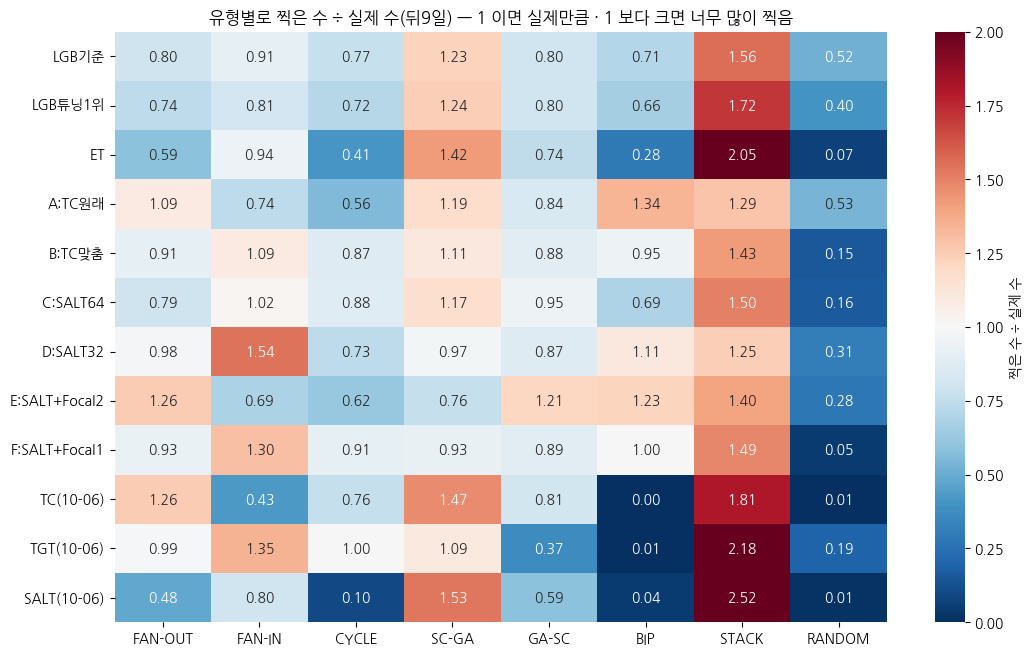

In [5]:
rows = []
for m in MODELS:
    c = CM[m]; p, r, f = pr_of(c)
    rows.append(dict(모델=m, 행=int(c.sum()), 정답률=np.trace(c) / c.sum(), macro정밀도=p.mean(), macro재현율=r.mean(), macroF1_참고=f.mean()))
SUM = pd.DataFrame(rows).set_index('모델'); display(SUM.round(4).style.background_gradient(cmap='Greens', subset=['정답률', 'macro정밀도', 'macro재현율', 'macroF1_참고']).format(precision=4))
PREC = pd.DataFrame({m: pr_of(CM[m])[0] for m in MODELS}, index=CN).T; REC = pd.DataFrame({m: pr_of(CM[m])[1] for m in MODELS}, index=CN).T
display(Markdown('**유형별 정밀도**')); display(PREC.style.background_gradient(cmap='Blues', axis=None).format('{:.3f}'))
display(Markdown('**유형별 재현율**')); display(REC.style.background_gradient(cmap='Oranges', axis=None).format('{:.3f}'))
CNT = pd.DataFrame({m: CM[m].sum(0) for m in MODELS}, index=CN).T; CNT.loc['(실제 개수)'] = CM[MODELS[0]].sum(1)
display(Markdown('**모델이 그 유형으로 찍은 개수**')); display(CNT)
ratio = CNT.iloc[:-1] / CNT.loc['(실제 개수)']
fig, ax = plt.subplots(figsize=(11, 0.45 * len(MODELS) + 1.5))
sns.heatmap(ratio, annot=True, fmt='.2f', cmap='RdBu_r', center=1.0, vmin=0, vmax=2, ax=ax, cbar_kws={'label': '찍은 수 ÷ 실제 수'})
ax.set_title(f'유형별로 찍은 수 ÷ 실제 수({PERIOD}) — 1 이면 실제만큼 · 1 보다 크면 너무 많이 찍음'); ax.set_xticklabels(SHORT, rotation=0); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()

## 2. 혼동 행렬(개수)
행 = 실제 유형 · 열 = 찍은 유형 · 칸 숫자 = 행 수. 대각선(맞힌 것) 밖에서 큰 칸이 많이 헷갈린 곳이다.

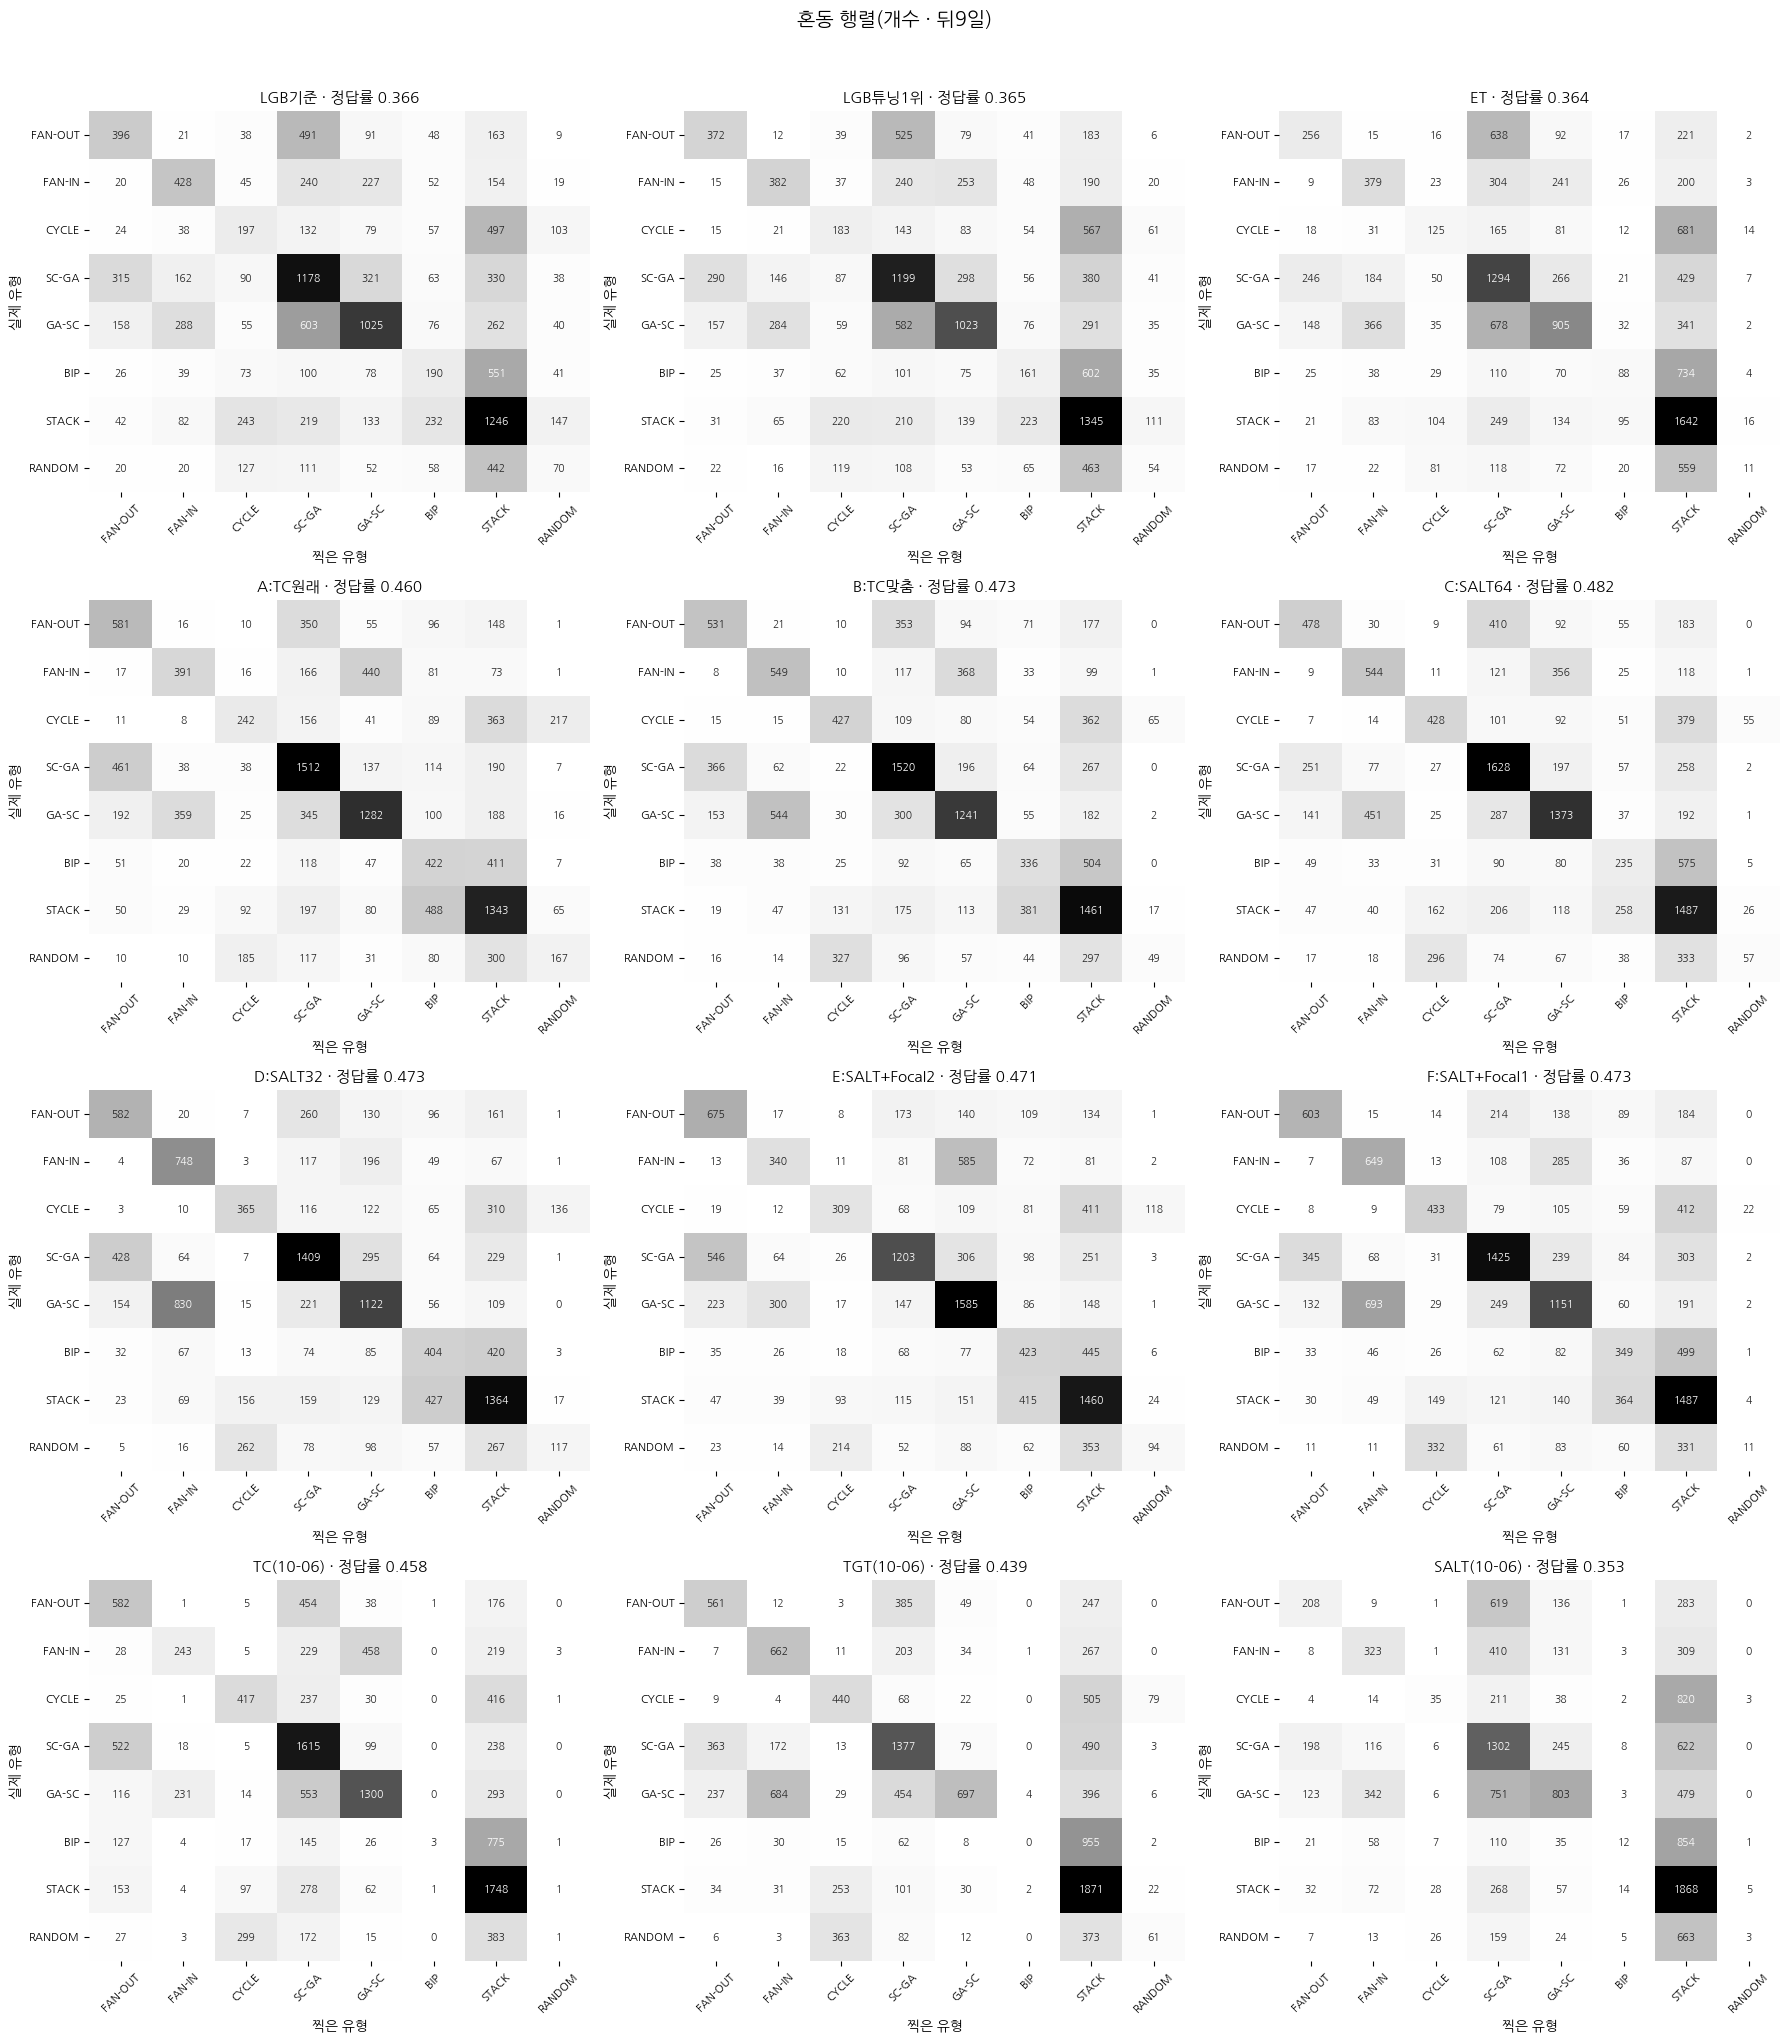

In [6]:
fig, ax = grid(len(MODELS))
for a, m in zip(ax, MODELS):
    sns.heatmap(CM[m], annot=True, fmt='d', cmap='Greys', cbar=False, ax=a, annot_kws={'size': 7.5}, xticklabels=SHORT, yticklabels=SHORT)
    a.set_title(f'{m} · 정답률 {np.trace(CM[m]) / CM[m].sum():.3f}', fontsize=11); a.set_xlabel('찍은 유형'); a.set_ylabel('실제 유형')
    a.tick_params(axis='x', rotation=45, labelsize=8); a.tick_params(axis='y', rotation=0, labelsize=8)
plt.suptitle(f'혼동 행렬(개수 · {PERIOD})', fontsize=14); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()

## 3. 혼동 행렬(%)
- **3-1 행 기준 %** — 실제 유형(행) 100% 가 어느 유형으로 갔나. 대각선 = 재현율.
- **3-2 열 기준 %** — 그 유형이라고 찍은 것(열) 100% 의 실제 구성. 대각선 = 정밀도. 그 유형을 거의 찍지 않았으면 열이 비어 있다(회색).

### 3-1. 행 기준 %

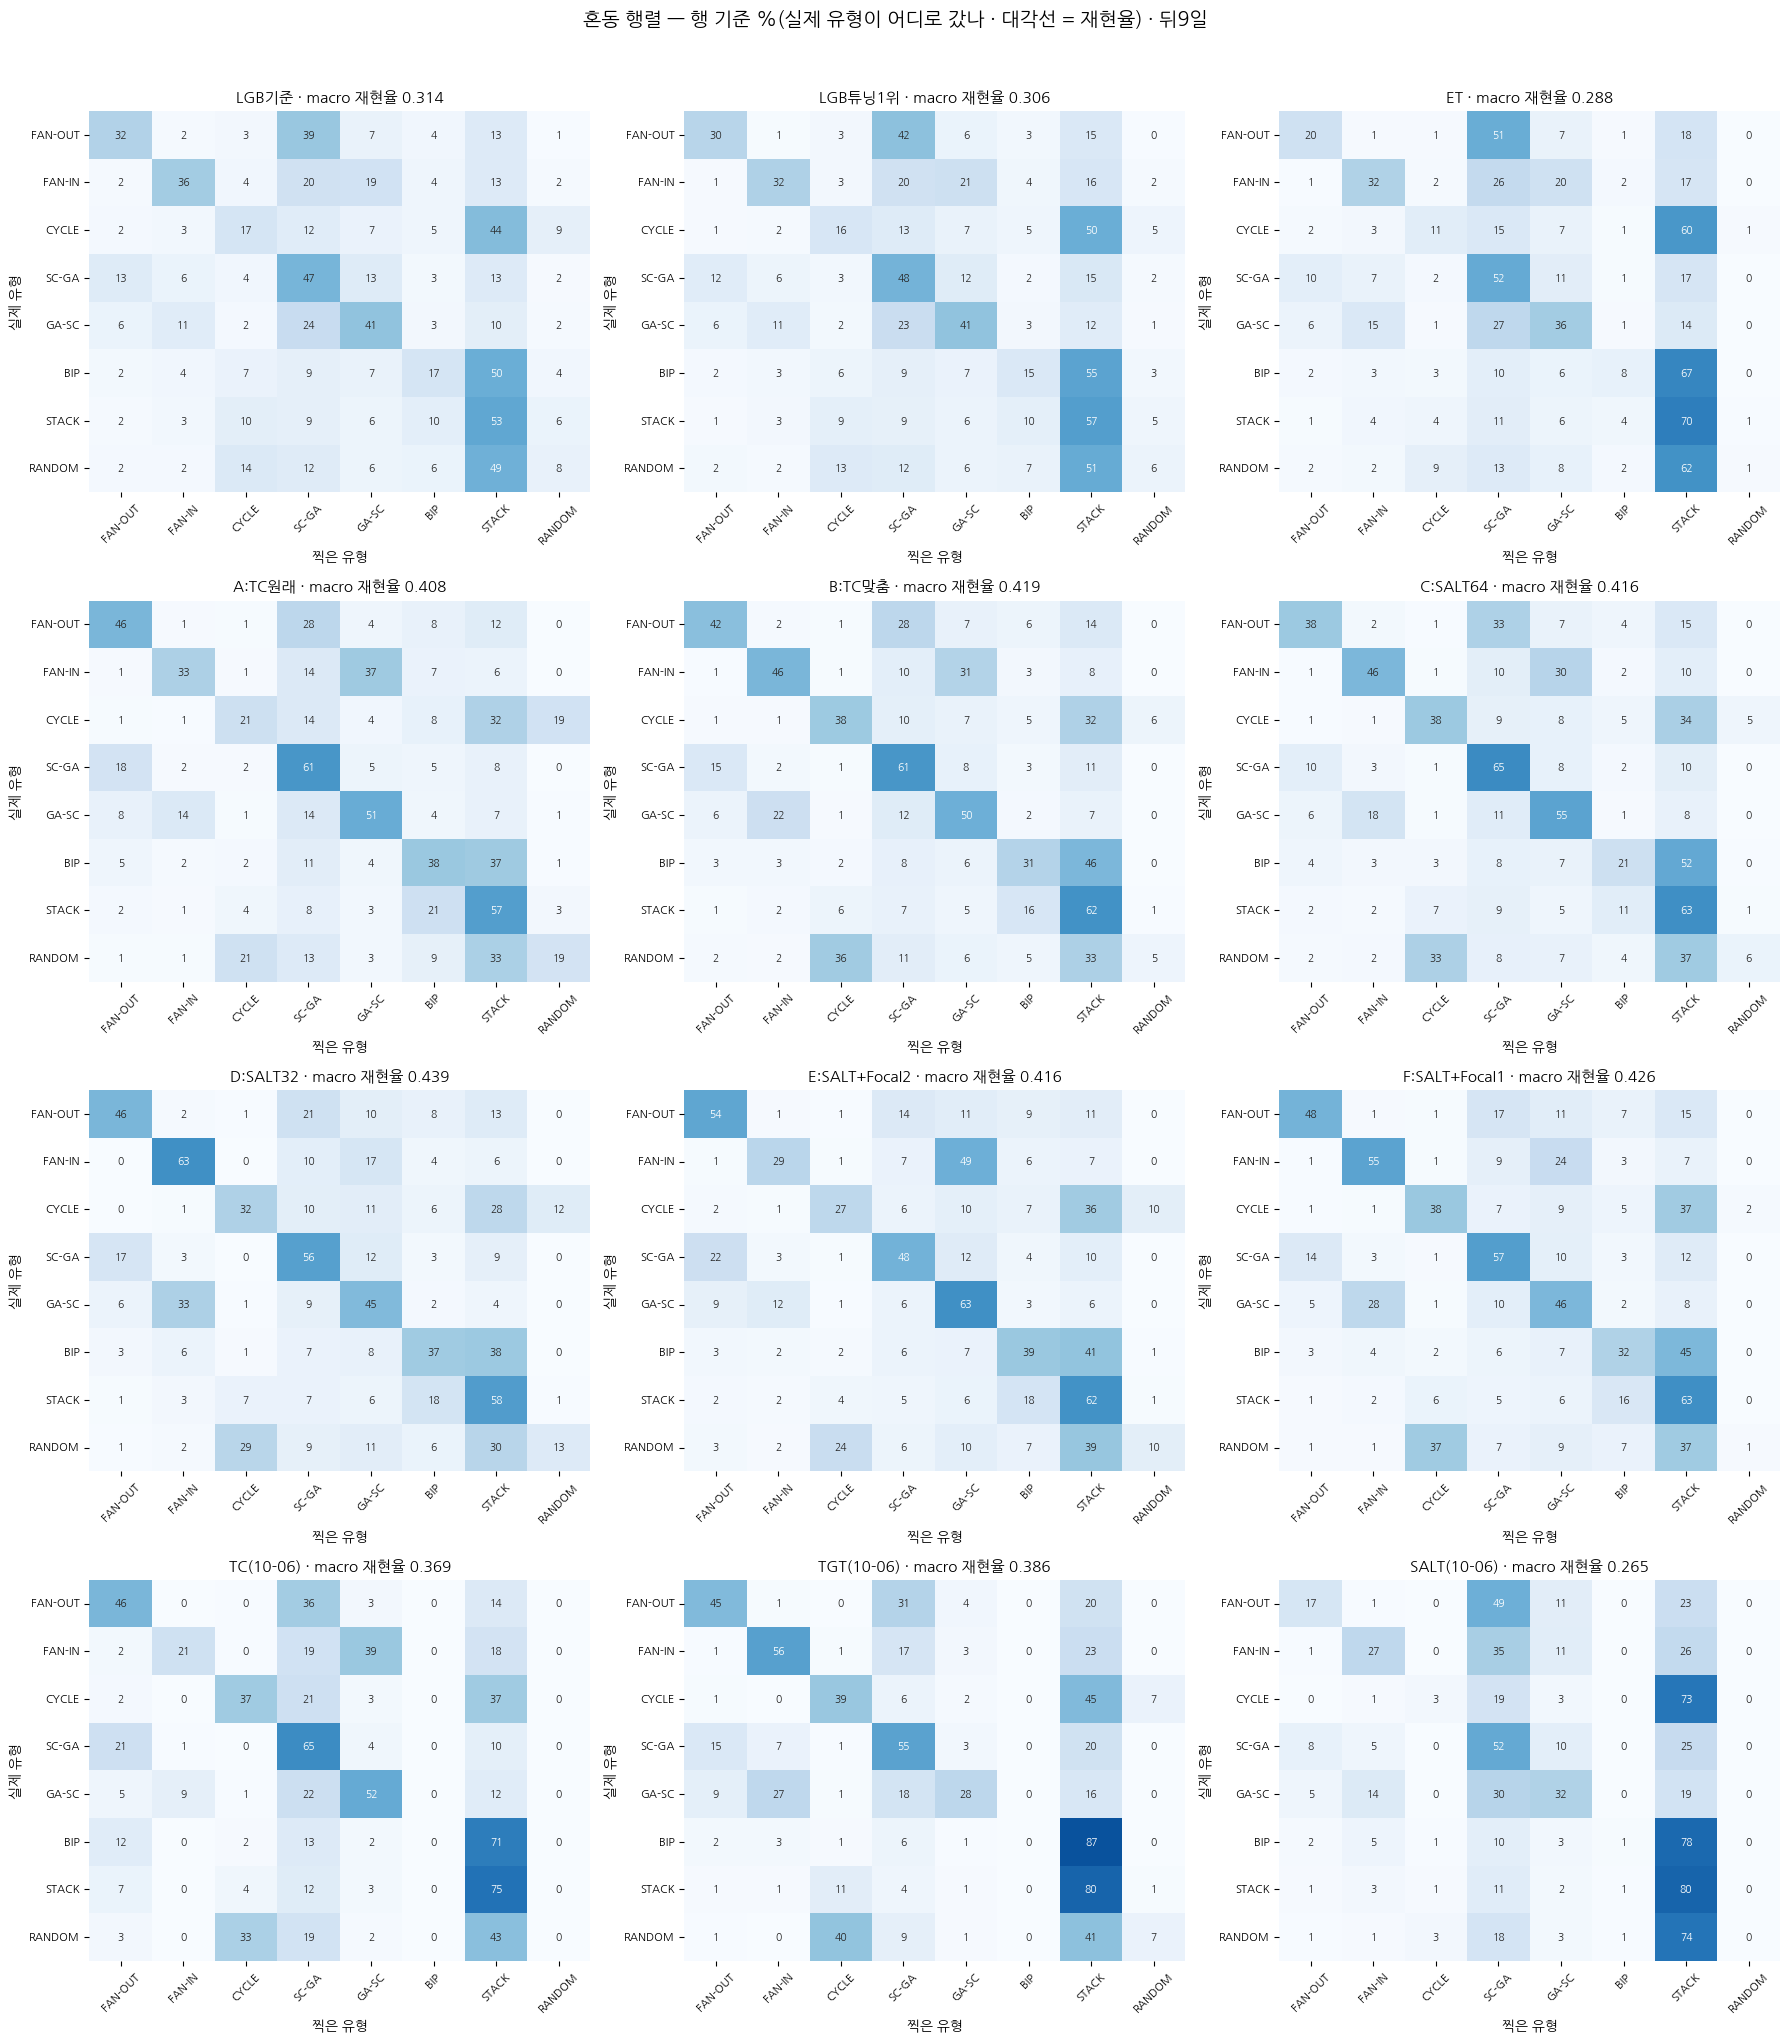

### 3-2. 열 기준 %

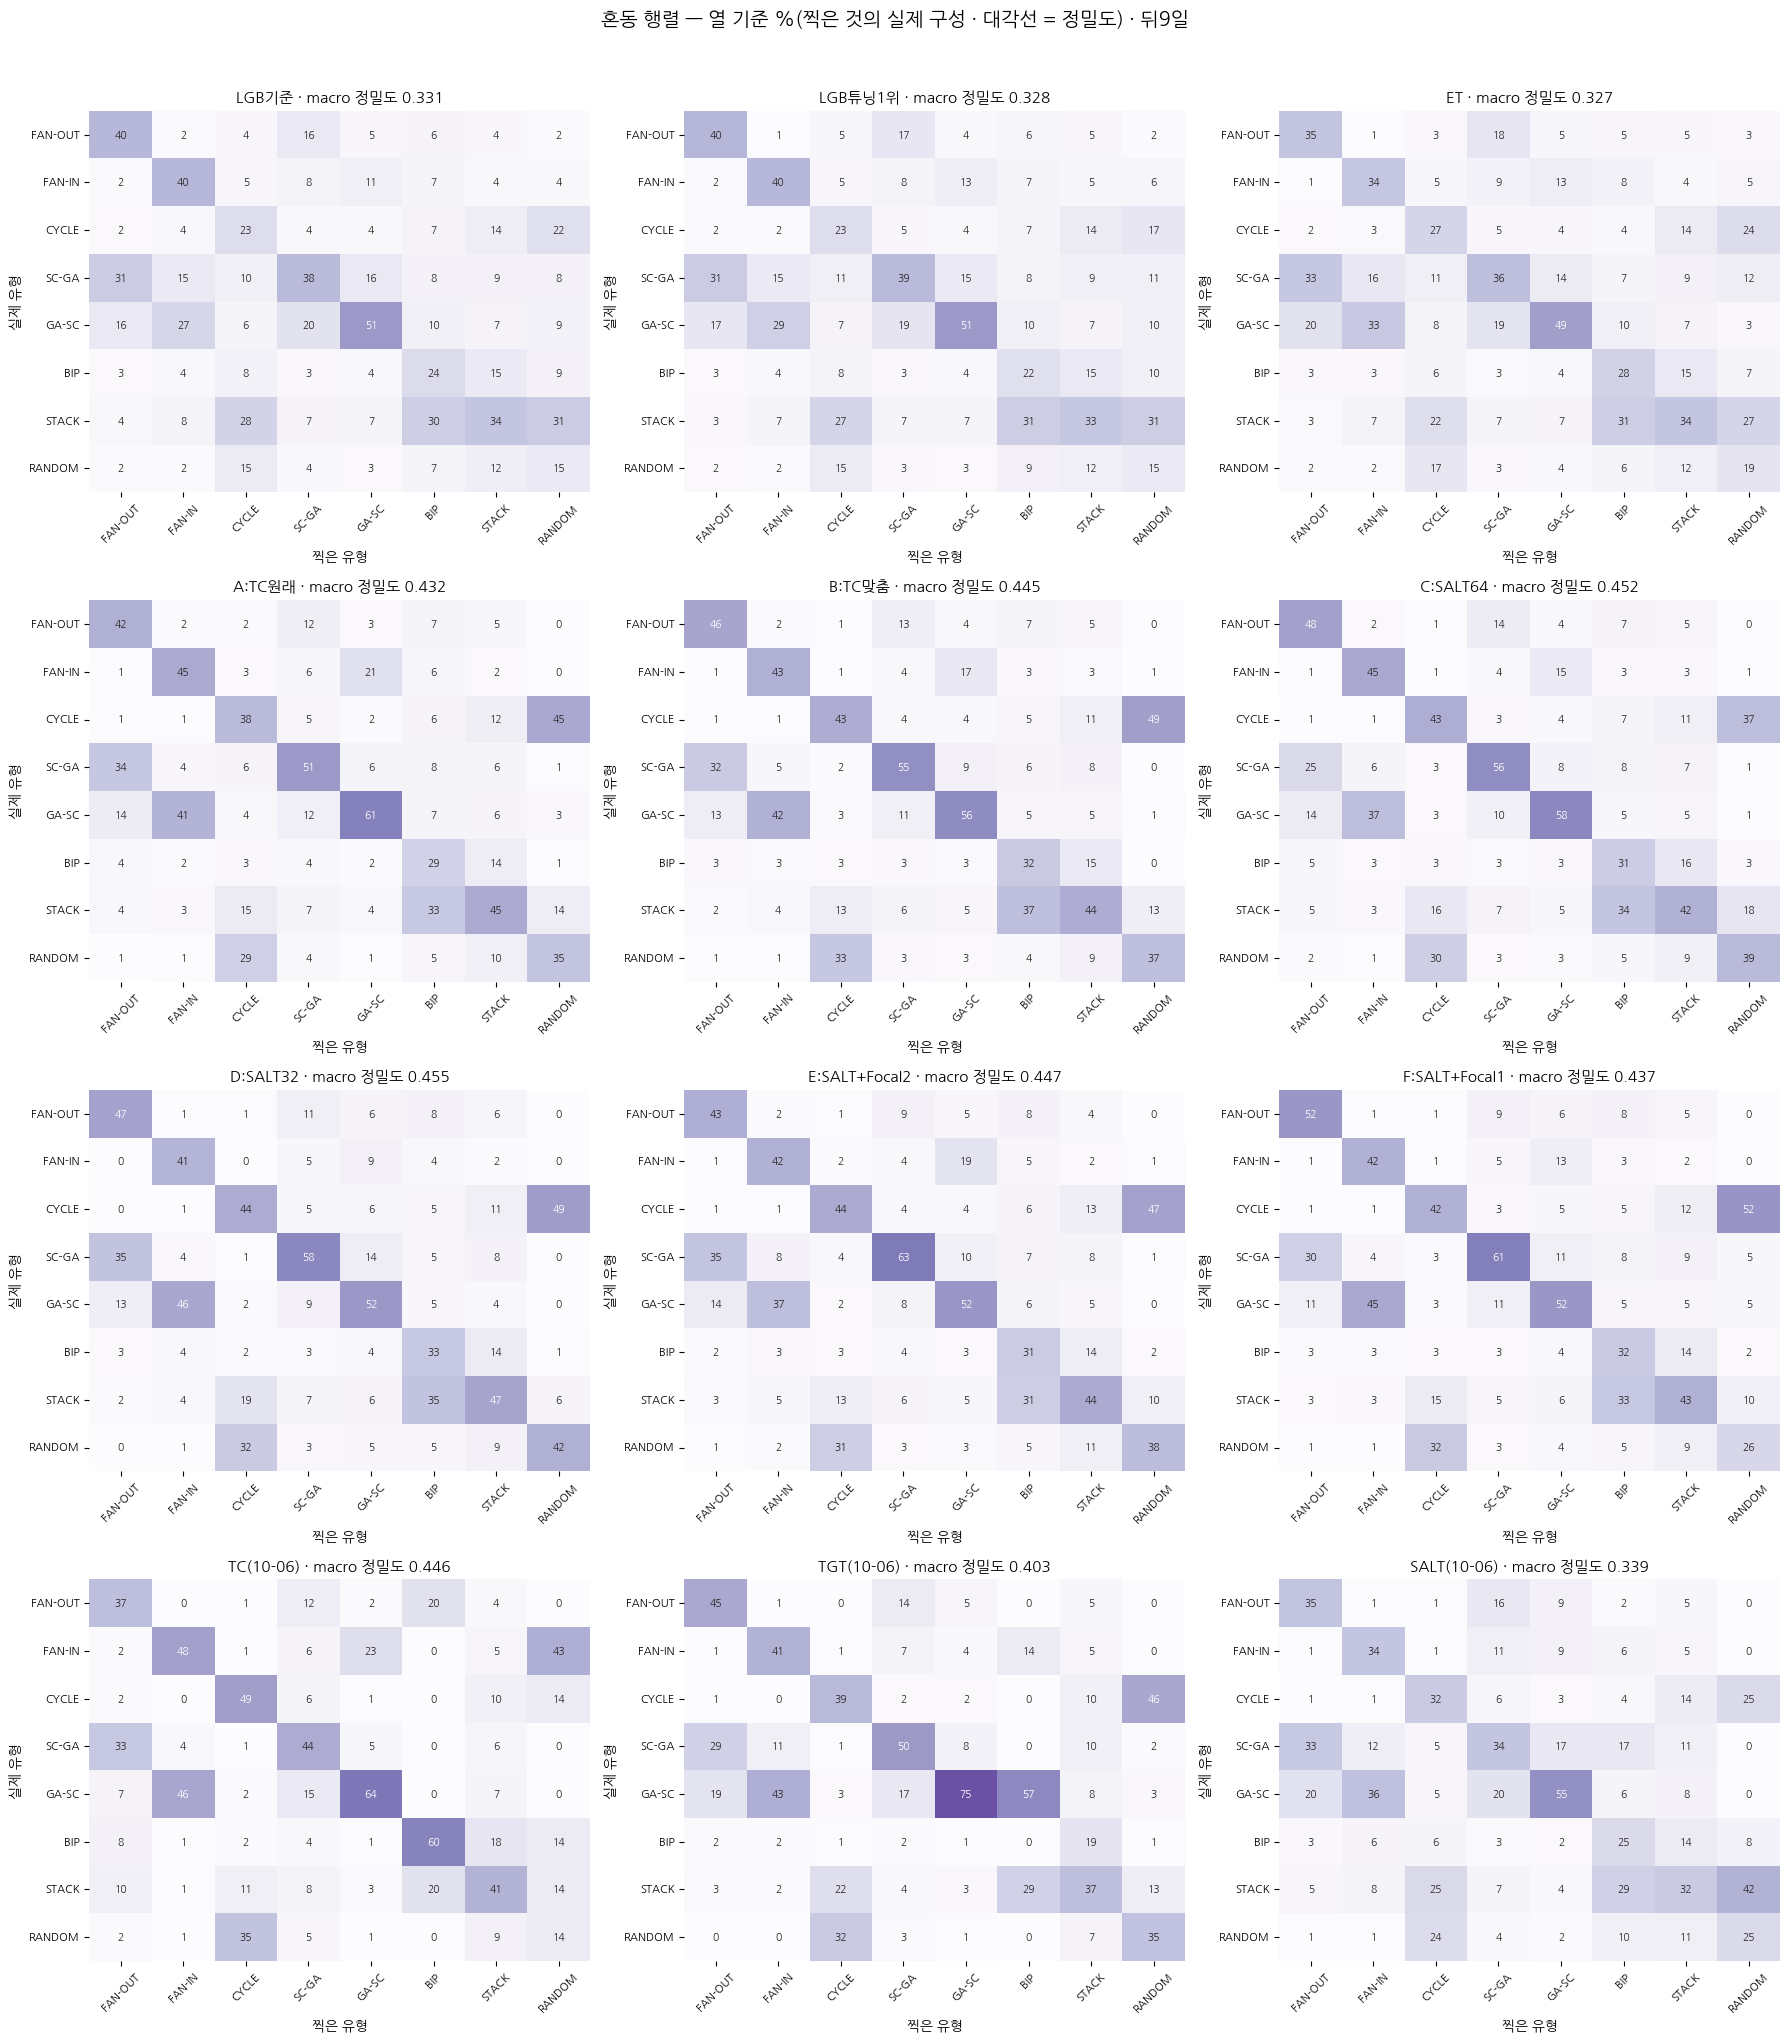

In [7]:
def pct_grid(kind):
    fig, ax = grid(len(MODELS))
    for a, m in zip(ax, MODELS):
        c = CM[m].astype(float)
        X = c / np.maximum(c.sum(1, keepdims=True), 1) if kind == 'row' else np.where(c.sum(0, keepdims=True) > 0, c / np.maximum(c.sum(0, keepdims=True), 1), np.nan)
        sns.heatmap(X * 100, annot=True, fmt='.0f', cmap='Blues' if kind == 'row' else 'Purples', vmin=0, vmax=100, cbar=False, ax=a, annot_kws={'size': 7.5},
                    xticklabels=SHORT, yticklabels=SHORT, mask=np.isnan(X))
        p, r, _ = pr_of(CM[m])
        a.set_title(f'{m} · macro {"재현율" if kind == "row" else "정밀도"} {(r if kind == "row" else p).mean():.3f}', fontsize=11)
        a.set_xlabel('찍은 유형'); a.set_ylabel('실제 유형'); a.tick_params(axis='x', rotation=45, labelsize=8); a.tick_params(axis='y', rotation=0, labelsize=8)
    plt.suptitle(f'혼동 행렬 — {"행 기준 %(실제 유형이 어디로 갔나 · 대각선 = 재현율)" if kind == "row" else "열 기준 %(찍은 것의 실제 구성 · 대각선 = 정밀도)"} · {PERIOD}', fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()
display(Markdown('### 3-1. 행 기준 %')); pct_grid('row')
display(Markdown('### 3-2. 열 기준 %')); pct_grid('col')

## 4. 실제 유형별 상세 — "이 유형은 어디로 갔나"
유형 8개를 하나씩: 그림 = 모델(행) × 찍은 유형(열)의 **%**(실제 그 유형 행 100% 기준), 표 = 같은 칸의 **개수**, 마지막 줄 = 모델마다 가장 많이 간 곳 3개.

### 4-1. 실제 **FAN-OUT** (1,257행)

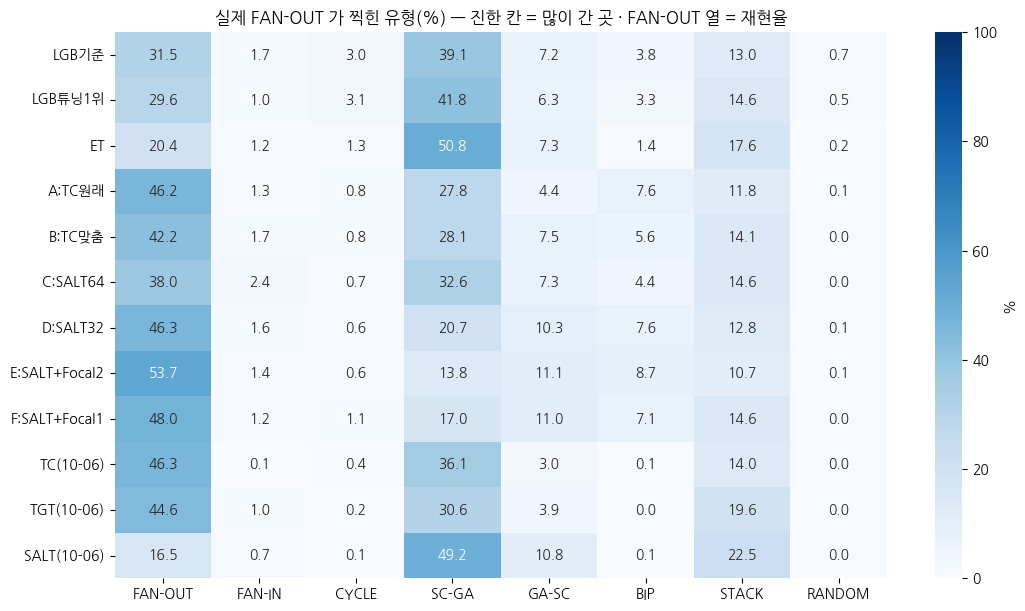

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,합
LGB기준,396,21,38,491,91,48,163,9,1257
LGB튜닝1위,372,12,39,525,79,41,183,6,1257
ET,256,15,16,638,92,17,221,2,1257
A:TC원래,581,16,10,350,55,96,148,1,1257
B:TC맞춤,531,21,10,353,94,71,177,0,1257
C:SALT64,478,30,9,410,92,55,183,0,1257
D:SALT32,582,20,7,260,130,96,161,1,1257
E:SALT+Focal2,675,17,8,173,140,109,134,1,1257
F:SALT+Focal1,603,15,14,214,138,89,184,0,1257
TC(10-06),582,1,5,454,38,1,176,0,1257


- **LGB기준**: SCATTER-GATHER 39.1% · FAN-OUT 31.5% · STACK 13.0%
- **LGB튜닝1위**: SCATTER-GATHER 41.8% · FAN-OUT 29.6% · STACK 14.6%
- **ET**: SCATTER-GATHER 50.8% · FAN-OUT 20.4% · STACK 17.6%
- **A:TC원래**: FAN-OUT 46.2% · SCATTER-GATHER 27.8% · STACK 11.8%
- **B:TC맞춤**: FAN-OUT 42.2% · SCATTER-GATHER 28.1% · STACK 14.1%
- **C:SALT64**: FAN-OUT 38.0% · SCATTER-GATHER 32.6% · STACK 14.6%
- **D:SALT32**: FAN-OUT 46.3% · SCATTER-GATHER 20.7% · STACK 12.8%
- **E:SALT+Focal2**: FAN-OUT 53.7% · SCATTER-GATHER 13.8% · GATHER-SCATTER 11.1%
- **F:SALT+Focal1**: FAN-OUT 48.0% · SCATTER-GATHER 17.0% · STACK 14.6%
- **TC(10-06)**: FAN-OUT 46.3% · SCATTER-GATHER 36.1% · STACK 14.0%
- **TGT(10-06)**: FAN-OUT 44.6% · SCATTER-GATHER 30.6% · STACK 19.6%
- **SALT(10-06)**: SCATTER-GATHER 49.2% · STACK 22.5% · FAN-OUT 16.5%

### 4-2. 실제 **FAN-IN** (1,185행)

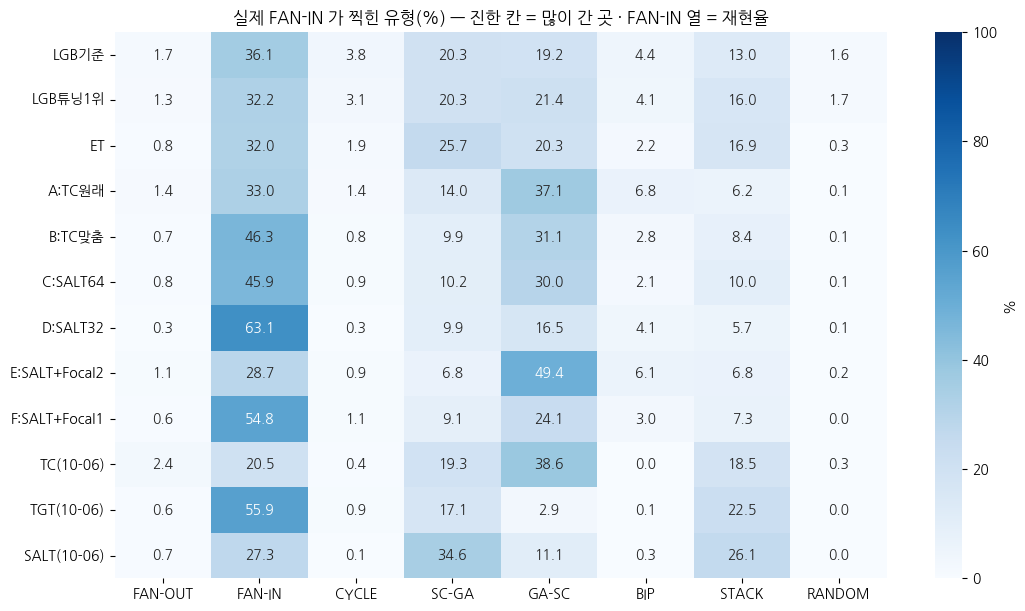

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,합
LGB기준,20,428,45,240,227,52,154,19,1185
LGB튜닝1위,15,382,37,240,253,48,190,20,1185
ET,9,379,23,304,241,26,200,3,1185
A:TC원래,17,391,16,166,440,81,73,1,1185
B:TC맞춤,8,549,10,117,368,33,99,1,1185
C:SALT64,9,544,11,121,356,25,118,1,1185
D:SALT32,4,748,3,117,196,49,67,1,1185
E:SALT+Focal2,13,340,11,81,585,72,81,2,1185
F:SALT+Focal1,7,649,13,108,285,36,87,0,1185
TC(10-06),28,243,5,229,458,0,219,3,1185


- **LGB기준**: FAN-IN 36.1% · SCATTER-GATHER 20.3% · GATHER-SCATTER 19.2%
- **LGB튜닝1위**: FAN-IN 32.2% · GATHER-SCATTER 21.4% · SCATTER-GATHER 20.3%
- **ET**: FAN-IN 32.0% · SCATTER-GATHER 25.7% · GATHER-SCATTER 20.3%
- **A:TC원래**: GATHER-SCATTER 37.1% · FAN-IN 33.0% · SCATTER-GATHER 14.0%
- **B:TC맞춤**: FAN-IN 46.3% · GATHER-SCATTER 31.1% · SCATTER-GATHER 9.9%
- **C:SALT64**: FAN-IN 45.9% · GATHER-SCATTER 30.0% · SCATTER-GATHER 10.2%
- **D:SALT32**: FAN-IN 63.1% · GATHER-SCATTER 16.5% · SCATTER-GATHER 9.9%
- **E:SALT+Focal2**: GATHER-SCATTER 49.4% · FAN-IN 28.7% · STACK 6.8%
- **F:SALT+Focal1**: FAN-IN 54.8% · GATHER-SCATTER 24.1% · SCATTER-GATHER 9.1%
- **TC(10-06)**: GATHER-SCATTER 38.6% · FAN-IN 20.5% · SCATTER-GATHER 19.3%
- **TGT(10-06)**: FAN-IN 55.9% · STACK 22.5% · SCATTER-GATHER 17.1%
- **SALT(10-06)**: SCATTER-GATHER 34.6% · FAN-IN 27.3% · STACK 26.1%

### 4-3. 실제 **CYCLE** (1,127행)

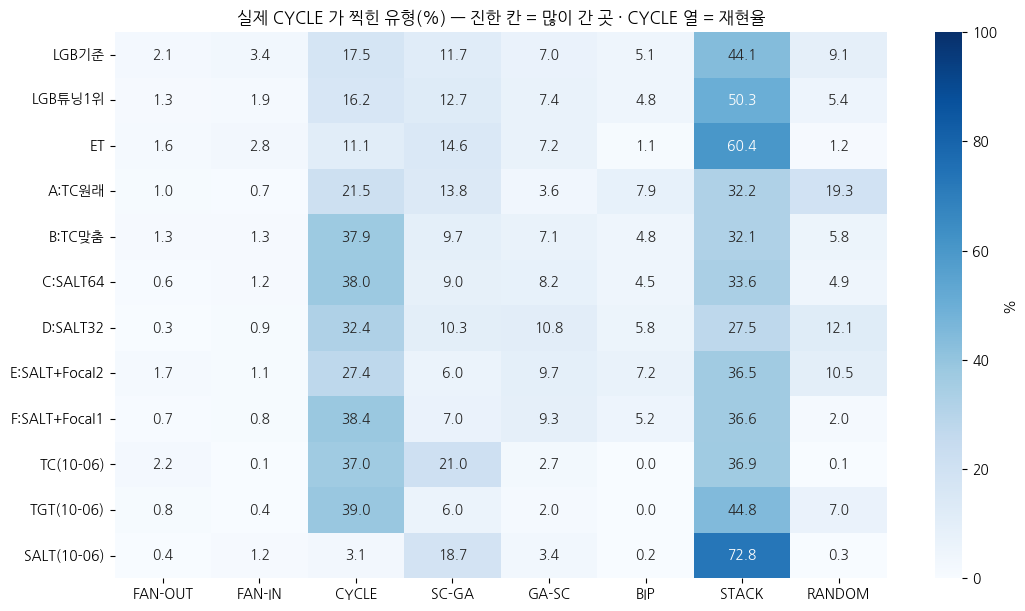

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,합
LGB기준,24,38,197,132,79,57,497,103,1127
LGB튜닝1위,15,21,183,143,83,54,567,61,1127
ET,18,31,125,165,81,12,681,14,1127
A:TC원래,11,8,242,156,41,89,363,217,1127
B:TC맞춤,15,15,427,109,80,54,362,65,1127
C:SALT64,7,14,428,101,92,51,379,55,1127
D:SALT32,3,10,365,116,122,65,310,136,1127
E:SALT+Focal2,19,12,309,68,109,81,411,118,1127
F:SALT+Focal1,8,9,433,79,105,59,412,22,1127
TC(10-06),25,1,417,237,30,0,416,1,1127


- **LGB기준**: STACK 44.1% · CYCLE 17.5% · SCATTER-GATHER 11.7%
- **LGB튜닝1위**: STACK 50.3% · CYCLE 16.2% · SCATTER-GATHER 12.7%
- **ET**: STACK 60.4% · SCATTER-GATHER 14.6% · CYCLE 11.1%
- **A:TC원래**: STACK 32.2% · CYCLE 21.5% · RANDOM 19.3%
- **B:TC맞춤**: CYCLE 37.9% · STACK 32.1% · SCATTER-GATHER 9.7%
- **C:SALT64**: CYCLE 38.0% · STACK 33.6% · SCATTER-GATHER 9.0%
- **D:SALT32**: CYCLE 32.4% · STACK 27.5% · RANDOM 12.1%
- **E:SALT+Focal2**: STACK 36.5% · CYCLE 27.4% · RANDOM 10.5%
- **F:SALT+Focal1**: CYCLE 38.4% · STACK 36.6% · GATHER-SCATTER 9.3%
- **TC(10-06)**: CYCLE 37.0% · STACK 36.9% · SCATTER-GATHER 21.0%
- **TGT(10-06)**: STACK 44.8% · CYCLE 39.0% · RANDOM 7.0%
- **SALT(10-06)**: STACK 72.8% · SCATTER-GATHER 18.7% · GATHER-SCATTER 3.4%

### 4-4. 실제 **SCATTER-GATHER** (2,497행)

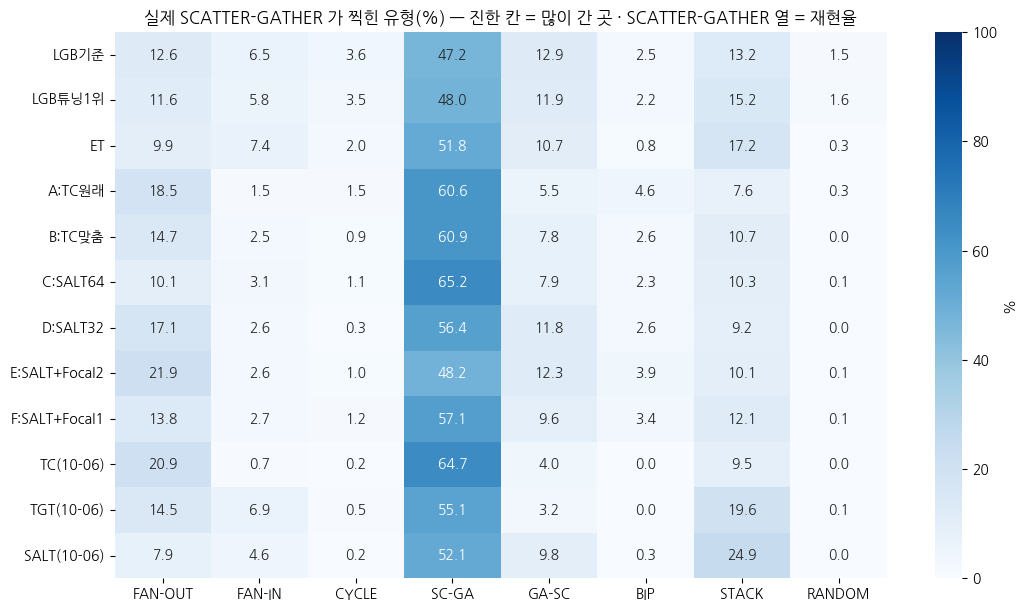

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,합
LGB기준,315,162,90,1178,321,63,330,38,2497
LGB튜닝1위,290,146,87,1199,298,56,380,41,2497
ET,246,184,50,1294,266,21,429,7,2497
A:TC원래,461,38,38,1512,137,114,190,7,2497
B:TC맞춤,366,62,22,1520,196,64,267,0,2497
C:SALT64,251,77,27,1628,197,57,258,2,2497
D:SALT32,428,64,7,1409,295,64,229,1,2497
E:SALT+Focal2,546,64,26,1203,306,98,251,3,2497
F:SALT+Focal1,345,68,31,1425,239,84,303,2,2497
TC(10-06),522,18,5,1615,99,0,238,0,2497


- **LGB기준**: SCATTER-GATHER 47.2% · STACK 13.2% · GATHER-SCATTER 12.9%
- **LGB튜닝1위**: SCATTER-GATHER 48.0% · STACK 15.2% · GATHER-SCATTER 11.9%
- **ET**: SCATTER-GATHER 51.8% · STACK 17.2% · GATHER-SCATTER 10.7%
- **A:TC원래**: SCATTER-GATHER 60.6% · FAN-OUT 18.5% · STACK 7.6%
- **B:TC맞춤**: SCATTER-GATHER 60.9% · FAN-OUT 14.7% · STACK 10.7%
- **C:SALT64**: SCATTER-GATHER 65.2% · STACK 10.3% · FAN-OUT 10.1%
- **D:SALT32**: SCATTER-GATHER 56.4% · FAN-OUT 17.1% · GATHER-SCATTER 11.8%
- **E:SALT+Focal2**: SCATTER-GATHER 48.2% · FAN-OUT 21.9% · GATHER-SCATTER 12.3%
- **F:SALT+Focal1**: SCATTER-GATHER 57.1% · FAN-OUT 13.8% · STACK 12.1%
- **TC(10-06)**: SCATTER-GATHER 64.7% · FAN-OUT 20.9% · STACK 9.5%
- **TGT(10-06)**: SCATTER-GATHER 55.1% · STACK 19.6% · FAN-OUT 14.5%
- **SALT(10-06)**: SCATTER-GATHER 52.1% · STACK 24.9% · GATHER-SCATTER 9.8%

### 4-5. 실제 **GATHER-SCATTER** (2,507행)

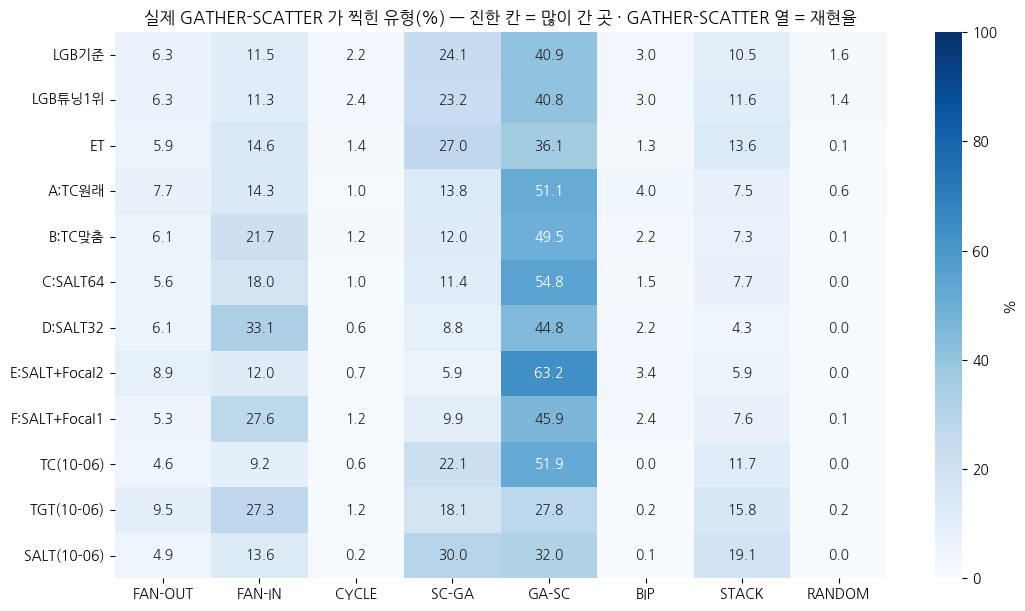

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,합
LGB기준,158,288,55,603,1025,76,262,40,2507
LGB튜닝1위,157,284,59,582,1023,76,291,35,2507
ET,148,366,35,678,905,32,341,2,2507
A:TC원래,192,359,25,345,1282,100,188,16,2507
B:TC맞춤,153,544,30,300,1241,55,182,2,2507
C:SALT64,141,451,25,287,1373,37,192,1,2507
D:SALT32,154,830,15,221,1122,56,109,0,2507
E:SALT+Focal2,223,300,17,147,1585,86,148,1,2507
F:SALT+Focal1,132,693,29,249,1151,60,191,2,2507
TC(10-06),116,231,14,553,1300,0,293,0,2507


- **LGB기준**: GATHER-SCATTER 40.9% · SCATTER-GATHER 24.1% · FAN-IN 11.5%
- **LGB튜닝1위**: GATHER-SCATTER 40.8% · SCATTER-GATHER 23.2% · STACK 11.6%
- **ET**: GATHER-SCATTER 36.1% · SCATTER-GATHER 27.0% · FAN-IN 14.6%
- **A:TC원래**: GATHER-SCATTER 51.1% · FAN-IN 14.3% · SCATTER-GATHER 13.8%
- **B:TC맞춤**: GATHER-SCATTER 49.5% · FAN-IN 21.7% · SCATTER-GATHER 12.0%
- **C:SALT64**: GATHER-SCATTER 54.8% · FAN-IN 18.0% · SCATTER-GATHER 11.4%
- **D:SALT32**: GATHER-SCATTER 44.8% · FAN-IN 33.1% · SCATTER-GATHER 8.8%
- **E:SALT+Focal2**: GATHER-SCATTER 63.2% · FAN-IN 12.0% · FAN-OUT 8.9%
- **F:SALT+Focal1**: GATHER-SCATTER 45.9% · FAN-IN 27.6% · SCATTER-GATHER 9.9%
- **TC(10-06)**: GATHER-SCATTER 51.9% · SCATTER-GATHER 22.1% · STACK 11.7%
- **TGT(10-06)**: GATHER-SCATTER 27.8% · FAN-IN 27.3% · SCATTER-GATHER 18.1%
- **SALT(10-06)**: GATHER-SCATTER 32.0% · SCATTER-GATHER 30.0% · STACK 19.1%

### 4-6. 실제 **BIPARTITE** (1,098행)

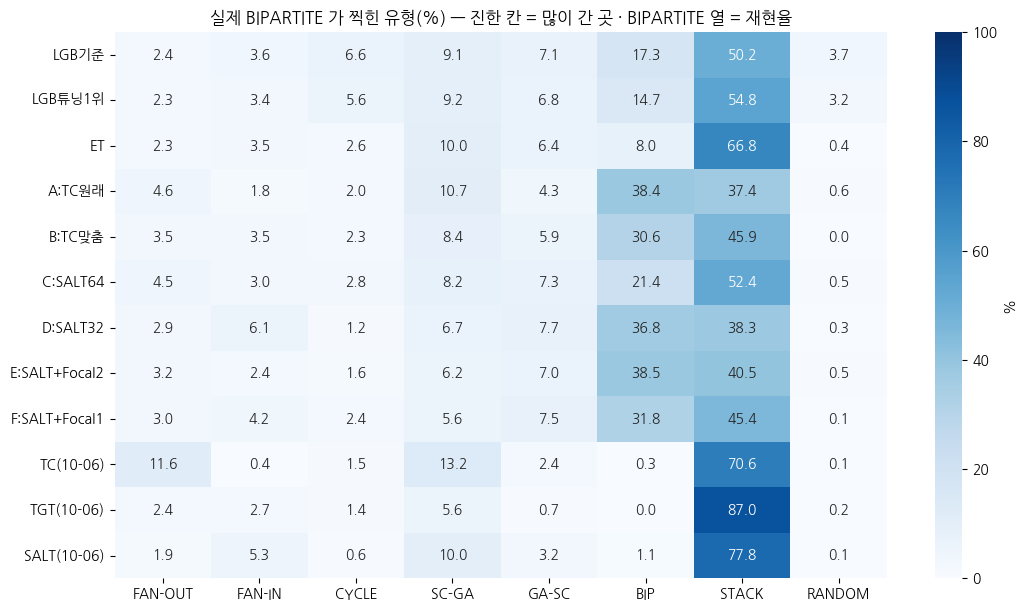

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,합
LGB기준,26,39,73,100,78,190,551,41,1098
LGB튜닝1위,25,37,62,101,75,161,602,35,1098
ET,25,38,29,110,70,88,734,4,1098
A:TC원래,51,20,22,118,47,422,411,7,1098
B:TC맞춤,38,38,25,92,65,336,504,0,1098
C:SALT64,49,33,31,90,80,235,575,5,1098
D:SALT32,32,67,13,74,85,404,420,3,1098
E:SALT+Focal2,35,26,18,68,77,423,445,6,1098
F:SALT+Focal1,33,46,26,62,82,349,499,1,1098
TC(10-06),127,4,17,145,26,3,775,1,1098


- **LGB기준**: STACK 50.2% · BIPARTITE 17.3% · SCATTER-GATHER 9.1%
- **LGB튜닝1위**: STACK 54.8% · BIPARTITE 14.7% · SCATTER-GATHER 9.2%
- **ET**: STACK 66.8% · SCATTER-GATHER 10.0% · BIPARTITE 8.0%
- **A:TC원래**: BIPARTITE 38.4% · STACK 37.4% · SCATTER-GATHER 10.7%
- **B:TC맞춤**: STACK 45.9% · BIPARTITE 30.6% · SCATTER-GATHER 8.4%
- **C:SALT64**: STACK 52.4% · BIPARTITE 21.4% · SCATTER-GATHER 8.2%
- **D:SALT32**: STACK 38.3% · BIPARTITE 36.8% · GATHER-SCATTER 7.7%
- **E:SALT+Focal2**: STACK 40.5% · BIPARTITE 38.5% · GATHER-SCATTER 7.0%
- **F:SALT+Focal1**: STACK 45.4% · BIPARTITE 31.8% · GATHER-SCATTER 7.5%
- **TC(10-06)**: STACK 70.6% · SCATTER-GATHER 13.2% · FAN-OUT 11.6%
- **TGT(10-06)**: STACK 87.0% · SCATTER-GATHER 5.6% · FAN-IN 2.7%
- **SALT(10-06)**: STACK 77.8% · SCATTER-GATHER 10.0% · FAN-IN 5.3%

### 4-7. 실제 **STACK** (2,344행)

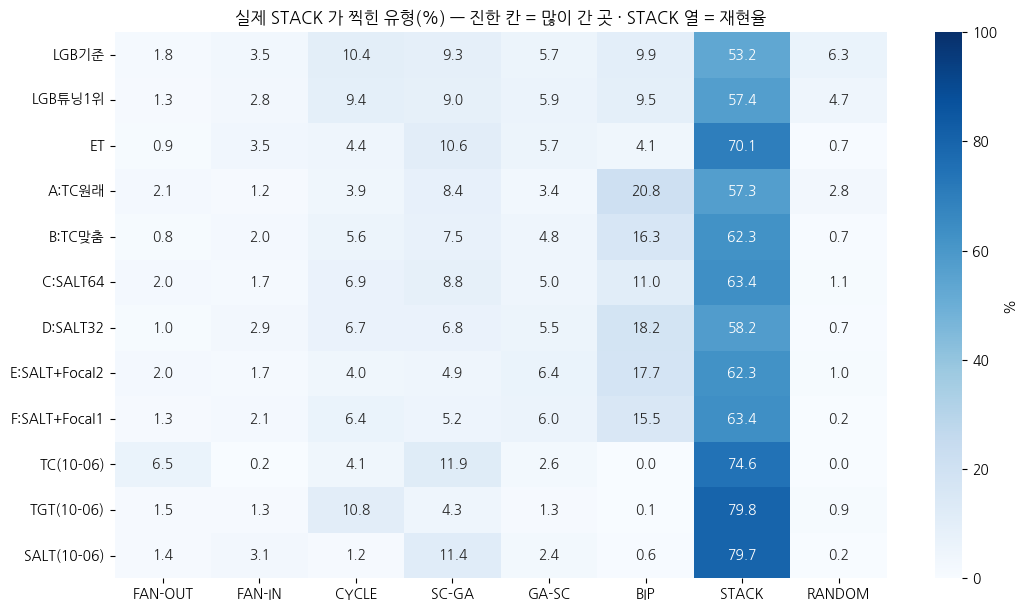

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,합
LGB기준,42,82,243,219,133,232,1246,147,2344
LGB튜닝1위,31,65,220,210,139,223,1345,111,2344
ET,21,83,104,249,134,95,1642,16,2344
A:TC원래,50,29,92,197,80,488,1343,65,2344
B:TC맞춤,19,47,131,175,113,381,1461,17,2344
C:SALT64,47,40,162,206,118,258,1487,26,2344
D:SALT32,23,69,156,159,129,427,1364,17,2344
E:SALT+Focal2,47,39,93,115,151,415,1460,24,2344
F:SALT+Focal1,30,49,149,121,140,364,1487,4,2344
TC(10-06),153,4,97,278,62,1,1748,1,2344


- **LGB기준**: STACK 53.2% · CYCLE 10.4% · BIPARTITE 9.9%
- **LGB튜닝1위**: STACK 57.4% · BIPARTITE 9.5% · CYCLE 9.4%
- **ET**: STACK 70.1% · SCATTER-GATHER 10.6% · GATHER-SCATTER 5.7%
- **A:TC원래**: STACK 57.3% · BIPARTITE 20.8% · SCATTER-GATHER 8.4%
- **B:TC맞춤**: STACK 62.3% · BIPARTITE 16.3% · SCATTER-GATHER 7.5%
- **C:SALT64**: STACK 63.4% · BIPARTITE 11.0% · SCATTER-GATHER 8.8%
- **D:SALT32**: STACK 58.2% · BIPARTITE 18.2% · SCATTER-GATHER 6.8%
- **E:SALT+Focal2**: STACK 62.3% · BIPARTITE 17.7% · GATHER-SCATTER 6.4%
- **F:SALT+Focal1**: STACK 63.4% · BIPARTITE 15.5% · CYCLE 6.4%
- **TC(10-06)**: STACK 74.6% · SCATTER-GATHER 11.9% · FAN-OUT 6.5%
- **TGT(10-06)**: STACK 79.8% · CYCLE 10.8% · SCATTER-GATHER 4.3%
- **SALT(10-06)**: STACK 79.7% · SCATTER-GATHER 11.4% · FAN-IN 3.1%

### 4-8. 실제 **RANDOM** (900행)

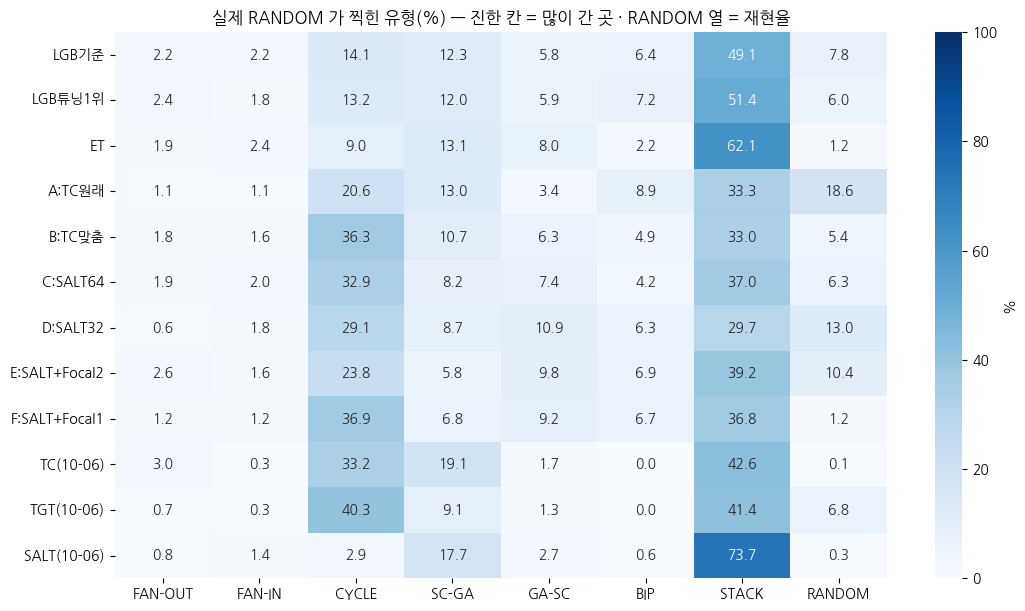

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,합
LGB기준,20,20,127,111,52,58,442,70,900
LGB튜닝1위,22,16,119,108,53,65,463,54,900
ET,17,22,81,118,72,20,559,11,900
A:TC원래,10,10,185,117,31,80,300,167,900
B:TC맞춤,16,14,327,96,57,44,297,49,900
C:SALT64,17,18,296,74,67,38,333,57,900
D:SALT32,5,16,262,78,98,57,267,117,900
E:SALT+Focal2,23,14,214,52,88,62,353,94,900
F:SALT+Focal1,11,11,332,61,83,60,331,11,900
TC(10-06),27,3,299,172,15,0,383,1,900


- **LGB기준**: STACK 49.1% · CYCLE 14.1% · SCATTER-GATHER 12.3%
- **LGB튜닝1위**: STACK 51.4% · CYCLE 13.2% · SCATTER-GATHER 12.0%
- **ET**: STACK 62.1% · SCATTER-GATHER 13.1% · CYCLE 9.0%
- **A:TC원래**: STACK 33.3% · CYCLE 20.6% · RANDOM 18.6%
- **B:TC맞춤**: CYCLE 36.3% · STACK 33.0% · SCATTER-GATHER 10.7%
- **C:SALT64**: STACK 37.0% · CYCLE 32.9% · SCATTER-GATHER 8.2%
- **D:SALT32**: STACK 29.7% · CYCLE 29.1% · RANDOM 13.0%
- **E:SALT+Focal2**: STACK 39.2% · CYCLE 23.8% · RANDOM 10.4%
- **F:SALT+Focal1**: CYCLE 36.9% · STACK 36.8% · GATHER-SCATTER 9.2%
- **TC(10-06)**: STACK 42.6% · CYCLE 33.2% · SCATTER-GATHER 19.1%
- **TGT(10-06)**: STACK 41.4% · CYCLE 40.3% · SCATTER-GATHER 9.1%
- **SALT(10-06)**: STACK 73.7% · SCATTER-GATHER 17.7% · CYCLE 2.9%

In [8]:
for k in range(K):
    n_k = int((y == k).sum())
    display(Markdown(f'### 4-{k + 1}. 실제 **{CN[k]}** ({n_k:,}행)'))
    Cn = pd.DataFrame([CM[m][k] for m in MODELS], index=MODELS, columns=CN); Pp = Cn.div(Cn.sum(1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(MODELS) + 1.4))
    sns.heatmap(Pp, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, ax=ax, cbar_kws={'label': '%'})
    ax.set_title(f'실제 {CN[k]} 가 찍힌 유형(%) — 진한 칸 = 많이 간 곳 · {CN[k]} 열 = 재현율'); ax.set_xticklabels(SHORT, rotation=0); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()
    display(Cn.assign(합=Cn.sum(1)))
    tops = []
    for m in MODELS:
        o = np.argsort(-CM[m][k])[:3]; tops.append(f'- **{m}**: ' + ' · '.join(f'{CN[j]} {CM[m][k, j] / max(n_k, 1) * 100:.1f}%' for j in o))
    display(Markdown('\n'.join(tops)))

## 5. 예측 유형별 상세 — "이 유형이라고 찍은 것은 실제로 무엇이었나"
그림 = 모델(행) × 실제 유형(열)의 **%**(그 유형이라고 찍은 행 100% 기준 · 자기 열 = 정밀도), 표 = 개수. 거의 찍지 않은 모델은 빈 줄이다.

### 5-1. **FAN-OUT** 라고 찍은 것

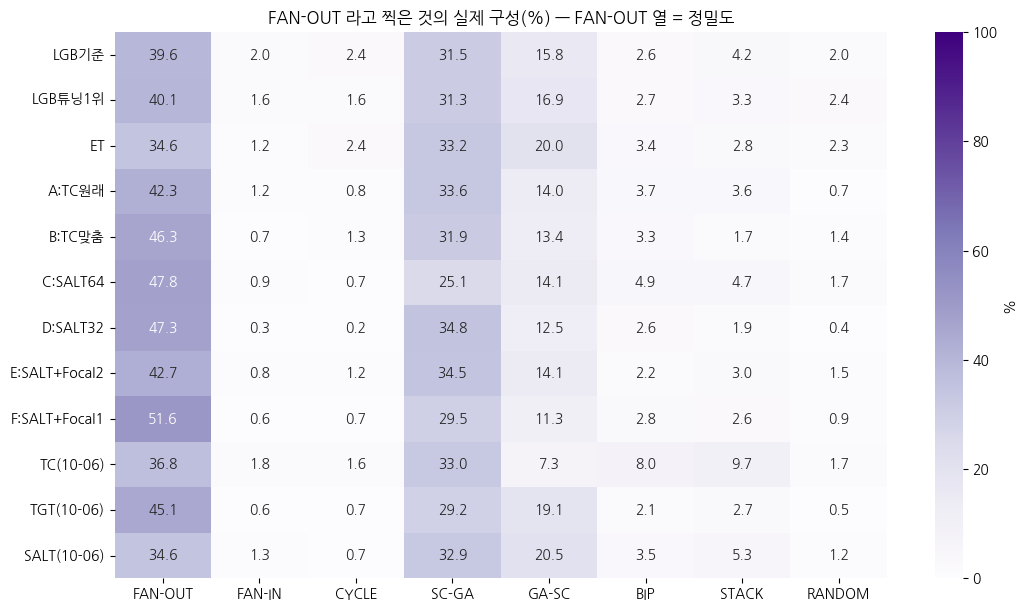

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,찍은_합
LGB기준,396,20,24,315,158,26,42,20,1001
LGB튜닝1위,372,15,15,290,157,25,31,22,927
ET,256,9,18,246,148,25,21,17,740
A:TC원래,581,17,11,461,192,51,50,10,1373
B:TC맞춤,531,8,15,366,153,38,19,16,1146
C:SALT64,478,9,7,251,141,49,47,17,999
D:SALT32,582,4,3,428,154,32,23,5,1231
E:SALT+Focal2,675,13,19,546,223,35,47,23,1581
F:SALT+Focal1,603,7,8,345,132,33,30,11,1169
TC(10-06),582,28,25,522,116,127,153,27,1580


### 5-2. **FAN-IN** 라고 찍은 것

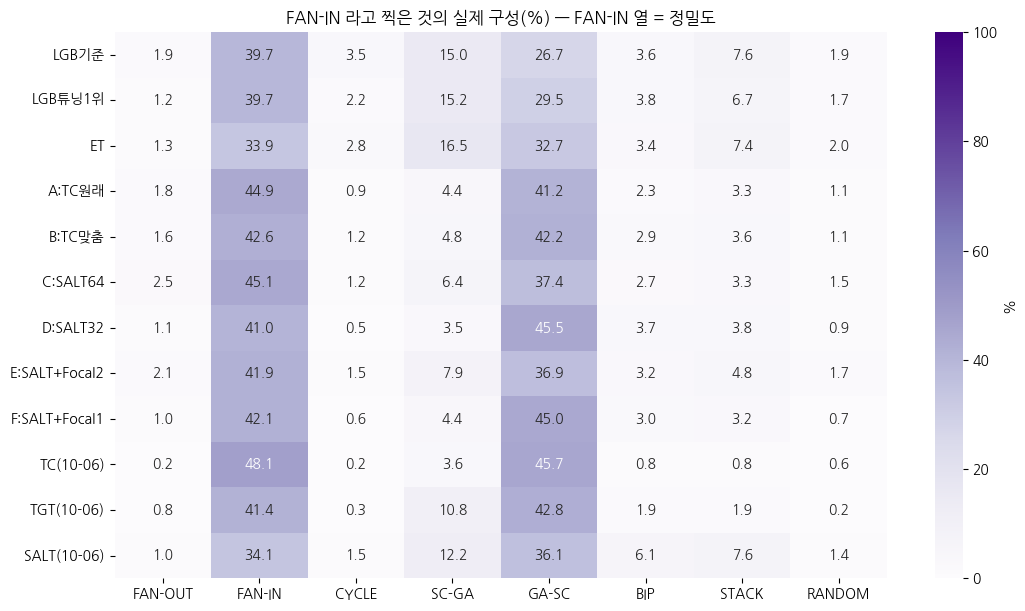

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,찍은_합
LGB기준,21,428,38,162,288,39,82,20,1078
LGB튜닝1위,12,382,21,146,284,37,65,16,963
ET,15,379,31,184,366,38,83,22,1118
A:TC원래,16,391,8,38,359,20,29,10,871
B:TC맞춤,21,549,15,62,544,38,47,14,1290
C:SALT64,30,544,14,77,451,33,40,18,1207
D:SALT32,20,748,10,64,830,67,69,16,1824
E:SALT+Focal2,17,340,12,64,300,26,39,14,812
F:SALT+Focal1,15,649,9,68,693,46,49,11,1540
TC(10-06),1,243,1,18,231,4,4,3,505


### 5-3. **CYCLE** 라고 찍은 것

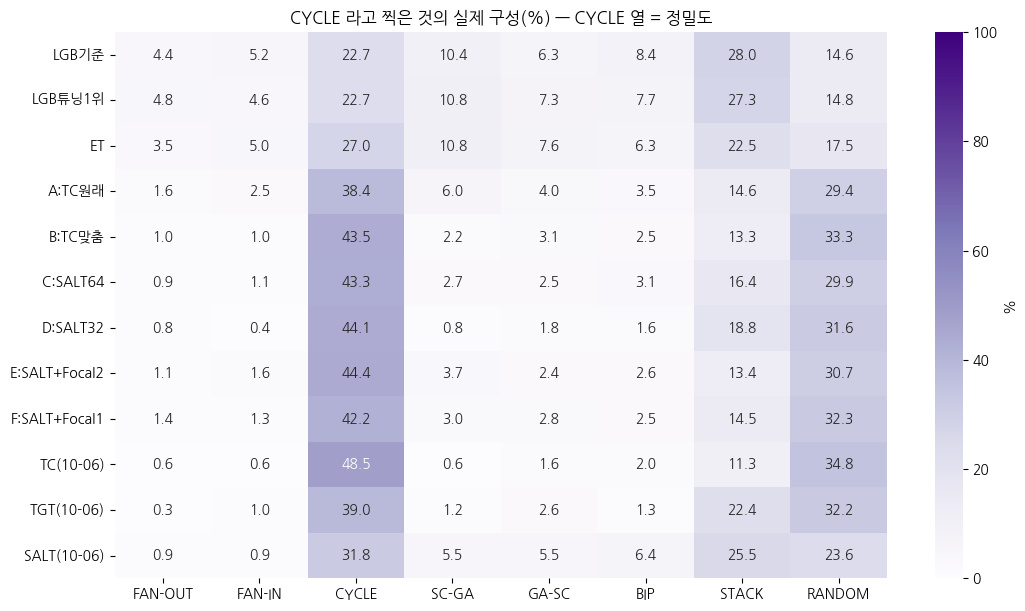

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,찍은_합
LGB기준,38,45,197,90,55,73,243,127,868
LGB튜닝1위,39,37,183,87,59,62,220,119,806
ET,16,23,125,50,35,29,104,81,463
A:TC원래,10,16,242,38,25,22,92,185,630
B:TC맞춤,10,10,427,22,30,25,131,327,982
C:SALT64,9,11,428,27,25,31,162,296,989
D:SALT32,7,3,365,7,15,13,156,262,828
E:SALT+Focal2,8,11,309,26,17,18,93,214,696
F:SALT+Focal1,14,13,433,31,29,26,149,332,1027
TC(10-06),5,5,417,5,14,17,97,299,859


### 5-4. **SCATTER-GATHER** 라고 찍은 것

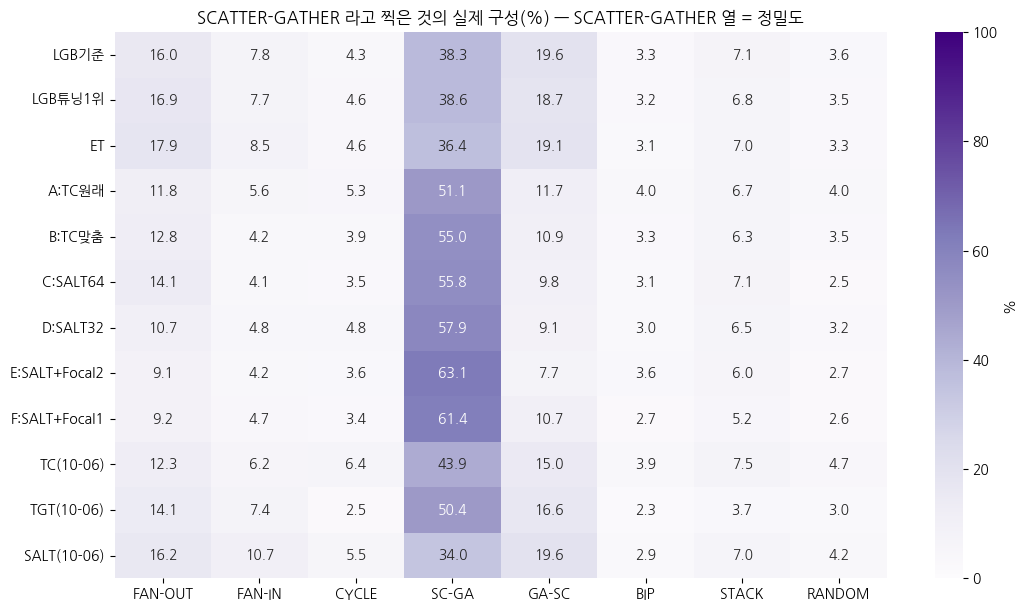

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,찍은_합
LGB기준,491,240,132,1178,603,100,219,111,3074
LGB튜닝1위,525,240,143,1199,582,101,210,108,3108
ET,638,304,165,1294,678,110,249,118,3556
A:TC원래,350,166,156,1512,345,118,197,117,2961
B:TC맞춤,353,117,109,1520,300,92,175,96,2762
C:SALT64,410,121,101,1628,287,90,206,74,2917
D:SALT32,260,117,116,1409,221,74,159,78,2434
E:SALT+Focal2,173,81,68,1203,147,68,115,52,1907
F:SALT+Focal1,214,108,79,1425,249,62,121,61,2319
TC(10-06),454,229,237,1615,553,145,278,172,3683


### 5-5. **GATHER-SCATTER** 라고 찍은 것

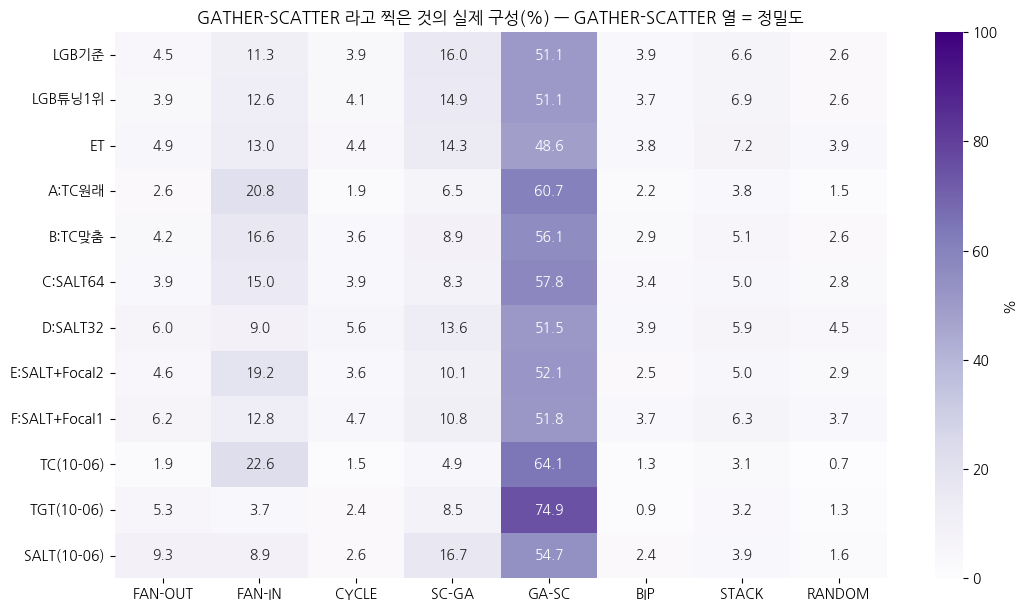

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,찍은_합
LGB기준,91,227,79,321,1025,78,133,52,2006
LGB튜닝1위,79,253,83,298,1023,75,139,53,2003
ET,92,241,81,266,905,70,134,72,1861
A:TC원래,55,440,41,137,1282,47,80,31,2113
B:TC맞춤,94,368,80,196,1241,65,113,57,2214
C:SALT64,92,356,92,197,1373,80,118,67,2375
D:SALT32,130,196,122,295,1122,85,129,98,2177
E:SALT+Focal2,140,585,109,306,1585,77,151,88,3041
F:SALT+Focal1,138,285,105,239,1151,82,140,83,2223
TC(10-06),38,458,30,99,1300,26,62,15,2028


### 5-6. **BIPARTITE** 라고 찍은 것

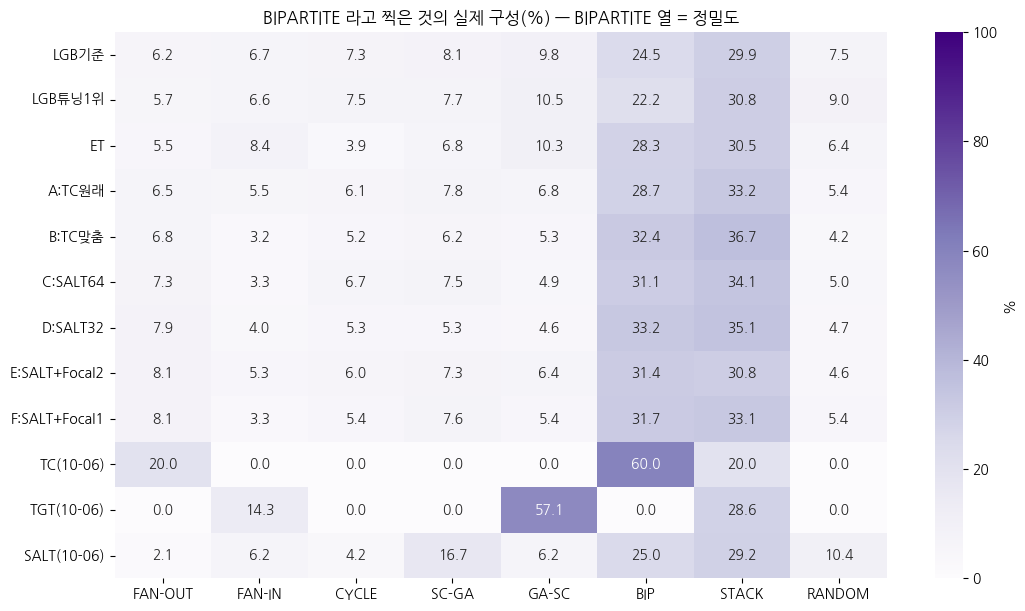

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,찍은_합
LGB기준,48,52,57,63,76,190,232,58,776
LGB튜닝1위,41,48,54,56,76,161,223,65,724
ET,17,26,12,21,32,88,95,20,311
A:TC원래,96,81,89,114,100,422,488,80,1470
B:TC맞춤,71,33,54,64,55,336,381,44,1038
C:SALT64,55,25,51,57,37,235,258,38,756
D:SALT32,96,49,65,64,56,404,427,57,1218
E:SALT+Focal2,109,72,81,98,86,423,415,62,1346
F:SALT+Focal1,89,36,59,84,60,349,364,60,1101
TC(10-06),1,0,0,0,0,3,1,0,5


### 5-7. **STACK** 라고 찍은 것

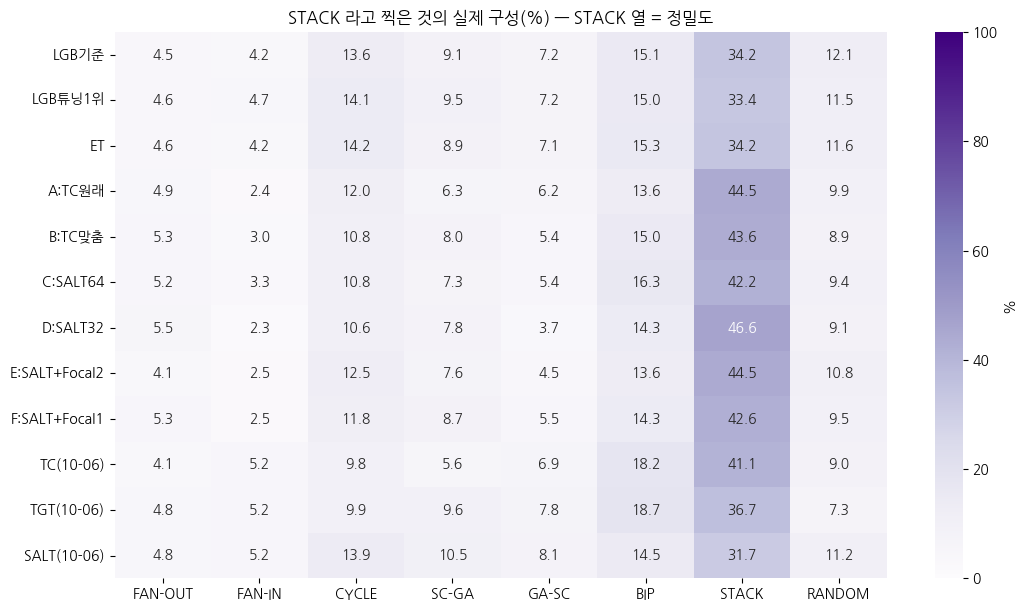

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,찍은_합
LGB기준,163,154,497,330,262,551,1246,442,3645
LGB튜닝1위,183,190,567,380,291,602,1345,463,4021
ET,221,200,681,429,341,734,1642,559,4807
A:TC원래,148,73,363,190,188,411,1343,300,3016
B:TC맞춤,177,99,362,267,182,504,1461,297,3349
C:SALT64,183,118,379,258,192,575,1487,333,3525
D:SALT32,161,67,310,229,109,420,1364,267,2927
E:SALT+Focal2,134,81,411,251,148,445,1460,353,3283
F:SALT+Focal1,184,87,412,303,191,499,1487,331,3494
TC(10-06),176,219,416,238,293,775,1748,383,4248


### 5-8. **RANDOM** 라고 찍은 것

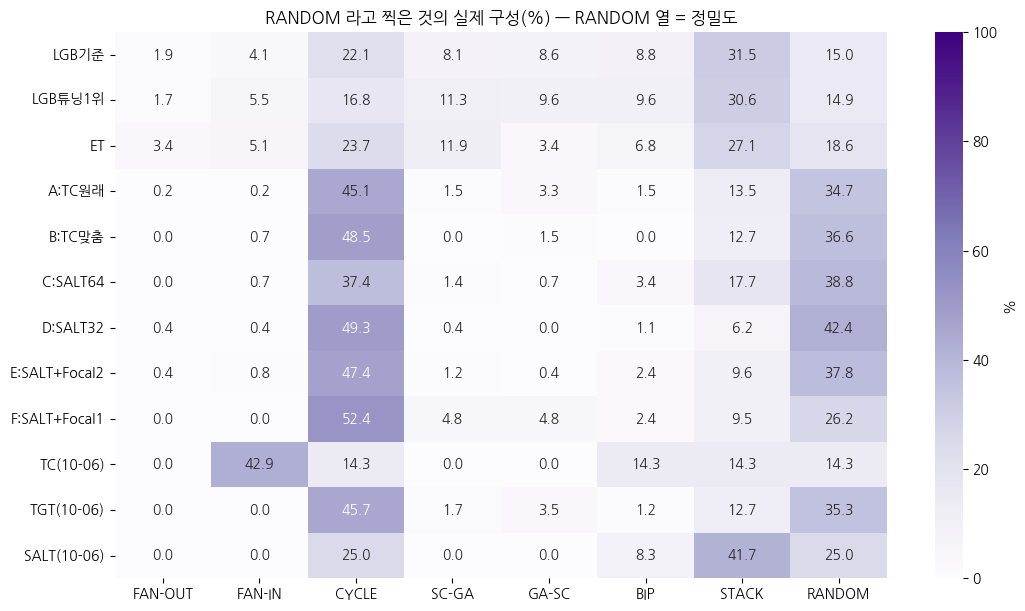

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM,찍은_합
LGB기준,9,19,103,38,40,41,147,70,467
LGB튜닝1위,6,20,61,41,35,35,111,54,363
ET,2,3,14,7,2,4,16,11,59
A:TC원래,1,1,217,7,16,7,65,167,481
B:TC맞춤,0,1,65,0,2,0,17,49,134
C:SALT64,0,1,55,2,1,5,26,57,147
D:SALT32,1,1,136,1,0,3,17,117,276
E:SALT+Focal2,1,2,118,3,1,6,24,94,249
F:SALT+Focal1,0,0,22,2,2,1,4,11,42
TC(10-06),0,3,1,0,0,1,1,1,7


In [9]:
for k in range(K):
    display(Markdown(f'### 5-{k + 1}. **{CN[k]}** 라고 찍은 것'))
    Cn = pd.DataFrame([CM[m][:, k] for m in MODELS], index=MODELS, columns=CN); tot = Cn.sum(1)
    Pp = Cn.div(tot.replace(0, np.nan), axis=0) * 100
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(MODELS) + 1.4))
    sns.heatmap(Pp, annot=True, fmt='.1f', cmap='Purples', vmin=0, vmax=100, ax=ax, cbar_kws={'label': '%'}, mask=Pp.isna())
    ax.set_title(f'{CN[k]} 라고 찍은 것의 실제 구성(%) — {CN[k]} 열 = 정밀도'); ax.set_xticklabels(SHORT, rotation=0); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()
    display(Cn.assign(찍은_합=tot))

## 6. 가장 많이 헷갈린 쌍
- 모델마다 대각선 밖 칸을 큰 순서로 `TOPN` 개. **실제 중 %** = 실제 그 유형 행 중 이 칸으로 간 비율 · **찍은 것 중 %** = 그 유형이라고 찍은 행 중 이 실제 유형의 비율.
- 마지막 표: 모든 모델의 쌍별 '실제 중 %' 를 한 표로(어느 모델이 그 혼동을 덜 하는지).

**LGB기준** — 오답 8,185행 중 상위 15쌍

,실제,찍은,개수,실제중_퍼센트,찍은것중_퍼센트
0,GATHER-SCATTER,SCATTER-GATHER,603,24.1,19.6
1,BIPARTITE,STACK,551,50.2,15.1
2,CYCLE,STACK,497,44.1,13.6
3,FAN-OUT,SCATTER-GATHER,491,39.1,16.0
4,RANDOM,STACK,442,49.1,12.1
5,SCATTER-GATHER,STACK,330,13.2,9.1
6,SCATTER-GATHER,GATHER-SCATTER,321,12.9,16.0
7,SCATTER-GATHER,FAN-OUT,315,12.6,31.5
8,GATHER-SCATTER,FAN-IN,288,11.5,26.7
9,GATHER-SCATTER,STACK,262,10.5,7.2


**LGB튜닝1위** — 오답 8,196행 중 상위 15쌍

,실제,찍은,개수,실제중_퍼센트,찍은것중_퍼센트
0,BIPARTITE,STACK,602,54.8,15.0
1,GATHER-SCATTER,SCATTER-GATHER,582,23.2,18.7
2,CYCLE,STACK,567,50.3,14.1
3,FAN-OUT,SCATTER-GATHER,525,41.8,16.9
4,RANDOM,STACK,463,51.4,11.5
5,SCATTER-GATHER,STACK,380,15.2,9.5
6,SCATTER-GATHER,GATHER-SCATTER,298,11.9,14.9
7,GATHER-SCATTER,STACK,291,11.6,7.2
8,SCATTER-GATHER,FAN-OUT,290,11.6,31.3
9,GATHER-SCATTER,FAN-IN,284,11.3,29.5


**ET** — 오답 8,215행 중 상위 15쌍

...

,실제,찍은,개수,실제중_퍼센트,찍은것중_퍼센트
0,BIPARTITE,STACK,775,70.6,18.2
1,GATHER-SCATTER,SCATTER-GATHER,553,22.1,15.0
2,SCATTER-GATHER,FAN-OUT,522,20.9,33.0
3,FAN-IN,GATHER-SCATTER,458,38.6,22.6
4,FAN-OUT,SCATTER-GATHER,454,36.1,12.3
5,CYCLE,STACK,416,36.9,9.8
6,RANDOM,STACK,383,42.6,9.0
7,RANDOM,CYCLE,299,33.2,34.8
8,GATHER-SCATTER,STACK,293,11.7,6.9
9,STACK,SCATTER-GATHER,278,11.9,7.5


**TGT(10-06)** — 오답 7,246행 중 상위 15쌍

,실제,찍은,개수,실제중_퍼센트,찍은것중_퍼센트
0,BIPARTITE,STACK,955,87.0,18.7
1,GATHER-SCATTER,FAN-IN,684,27.3,42.8
2,CYCLE,STACK,505,44.8,9.9
3,SCATTER-GATHER,STACK,490,19.6,9.6
4,GATHER-SCATTER,SCATTER-GATHER,454,18.1,16.6
5,GATHER-SCATTER,STACK,396,15.8,7.8
6,FAN-OUT,SCATTER-GATHER,385,30.6,14.1
7,RANDOM,STACK,373,41.4,7.3
8,SCATTER-GATHER,FAN-OUT,363,14.5,29.2
9,RANDOM,CYCLE,363,40.3,32.2


**SALT(10-06)** — 오답 8,361행 중 상위 15쌍

,실제,찍은,개수,실제중_퍼센트,찍은것중_퍼센트
0,BIPARTITE,STACK,854,77.8,14.5
1,CYCLE,STACK,820,72.8,13.9
2,GATHER-SCATTER,SCATTER-GATHER,751,30.0,19.6
3,RANDOM,STACK,663,73.7,11.2
4,SCATTER-GATHER,STACK,622,24.9,10.5
5,FAN-OUT,SCATTER-GATHER,619,49.2,16.2
6,GATHER-SCATTER,STACK,479,19.1,8.1
7,FAN-IN,SCATTER-GATHER,410,34.6,10.7
8,GATHER-SCATTER,FAN-IN,342,13.6,36.1
9,FAN-IN,STACK,309,26.1,5.2


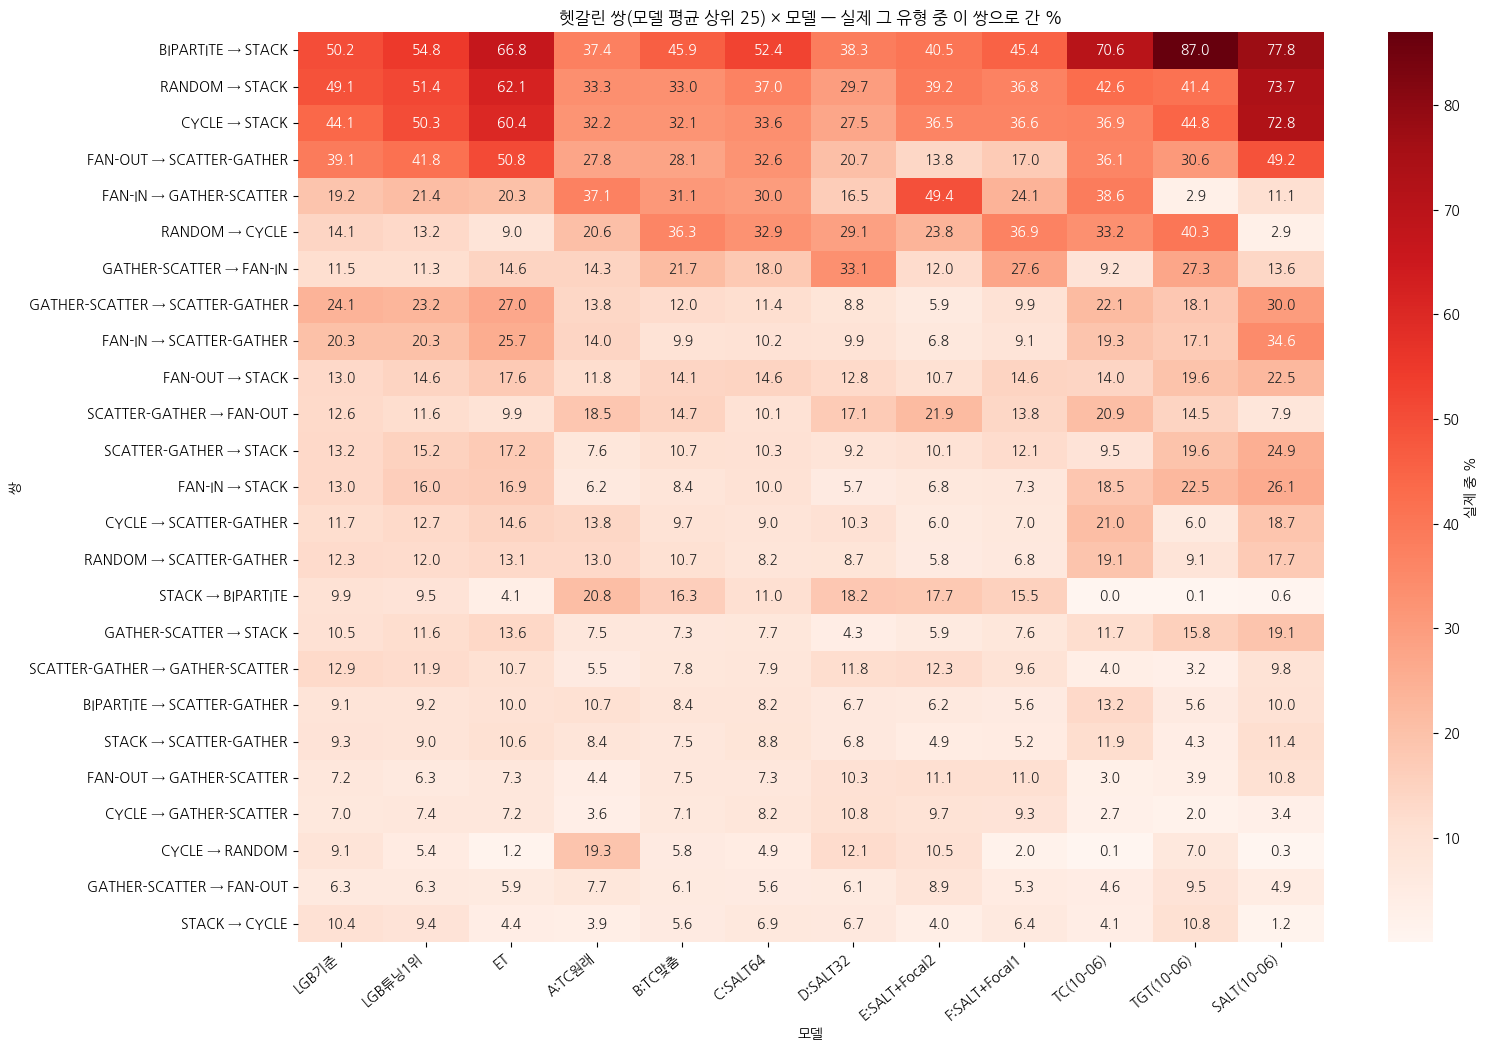

In [10]:
pair_rows = []
for m in MODELS:
    c = CM[m]; rs, cs = c.sum(1), c.sum(0); L = []
    for i in range(K):
        for j in range(K):
            if i != j and c[i, j] > 0:
                L.append(dict(모델=m, 실제=CN[i], 찍은=CN[j], 개수=int(c[i, j]), 실제중_퍼센트=c[i, j] / rs[i] * 100, 찍은것중_퍼센트=c[i, j] / cs[j] * 100))
    T = pd.DataFrame(L).sort_values('개수', ascending=False).head(TOPN); pair_rows.append(pd.DataFrame(L))
    display(Markdown(f'**{m}** — 오답 {int(c.sum() - np.trace(c)):,}행 중 상위 {TOPN}쌍'))
    display(T.drop(columns='모델').reset_index(drop=True).round(1))
ALLP = pd.concat(pair_rows); ALLP['쌍'] = ALLP['실제'] + ' → ' + ALLP['찍은']
PV = ALLP.pivot_table(index='쌍', columns='모델', values='실제중_퍼센트', fill_value=0)[MODELS]
PV = PV.loc[PV.mean(1).sort_values(ascending=False).index].head(25)
fig, ax = plt.subplots(figsize=(1.0 * len(MODELS) + 4, 0.38 * len(PV) + 1.5))
sns.heatmap(PV, annot=True, fmt='.1f', cmap='Reds', ax=ax, cbar_kws={'label': '실제 중 %'})
ax.set_title('헷갈린 쌍(모델 평균 상위 25) × 모델 — 실제 그 유형 중 이 쌍으로 간 %'); plt.xticks(rotation=40, ha='right'); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()

## 7. 틀렸을 때 정답은 몇 순위였나
확률이 있는 모델만. 모델이 8유형에 매긴 확률 순위에서 **정답 유형이 몇 번째였는지**(1 = 맞힘). 2 · 3순위가 많으면 "거의 맞힌" 오답이다. 표 = 유형별 1위 · 2위 안 · 3위 안 비율(top-1 = 재현율).

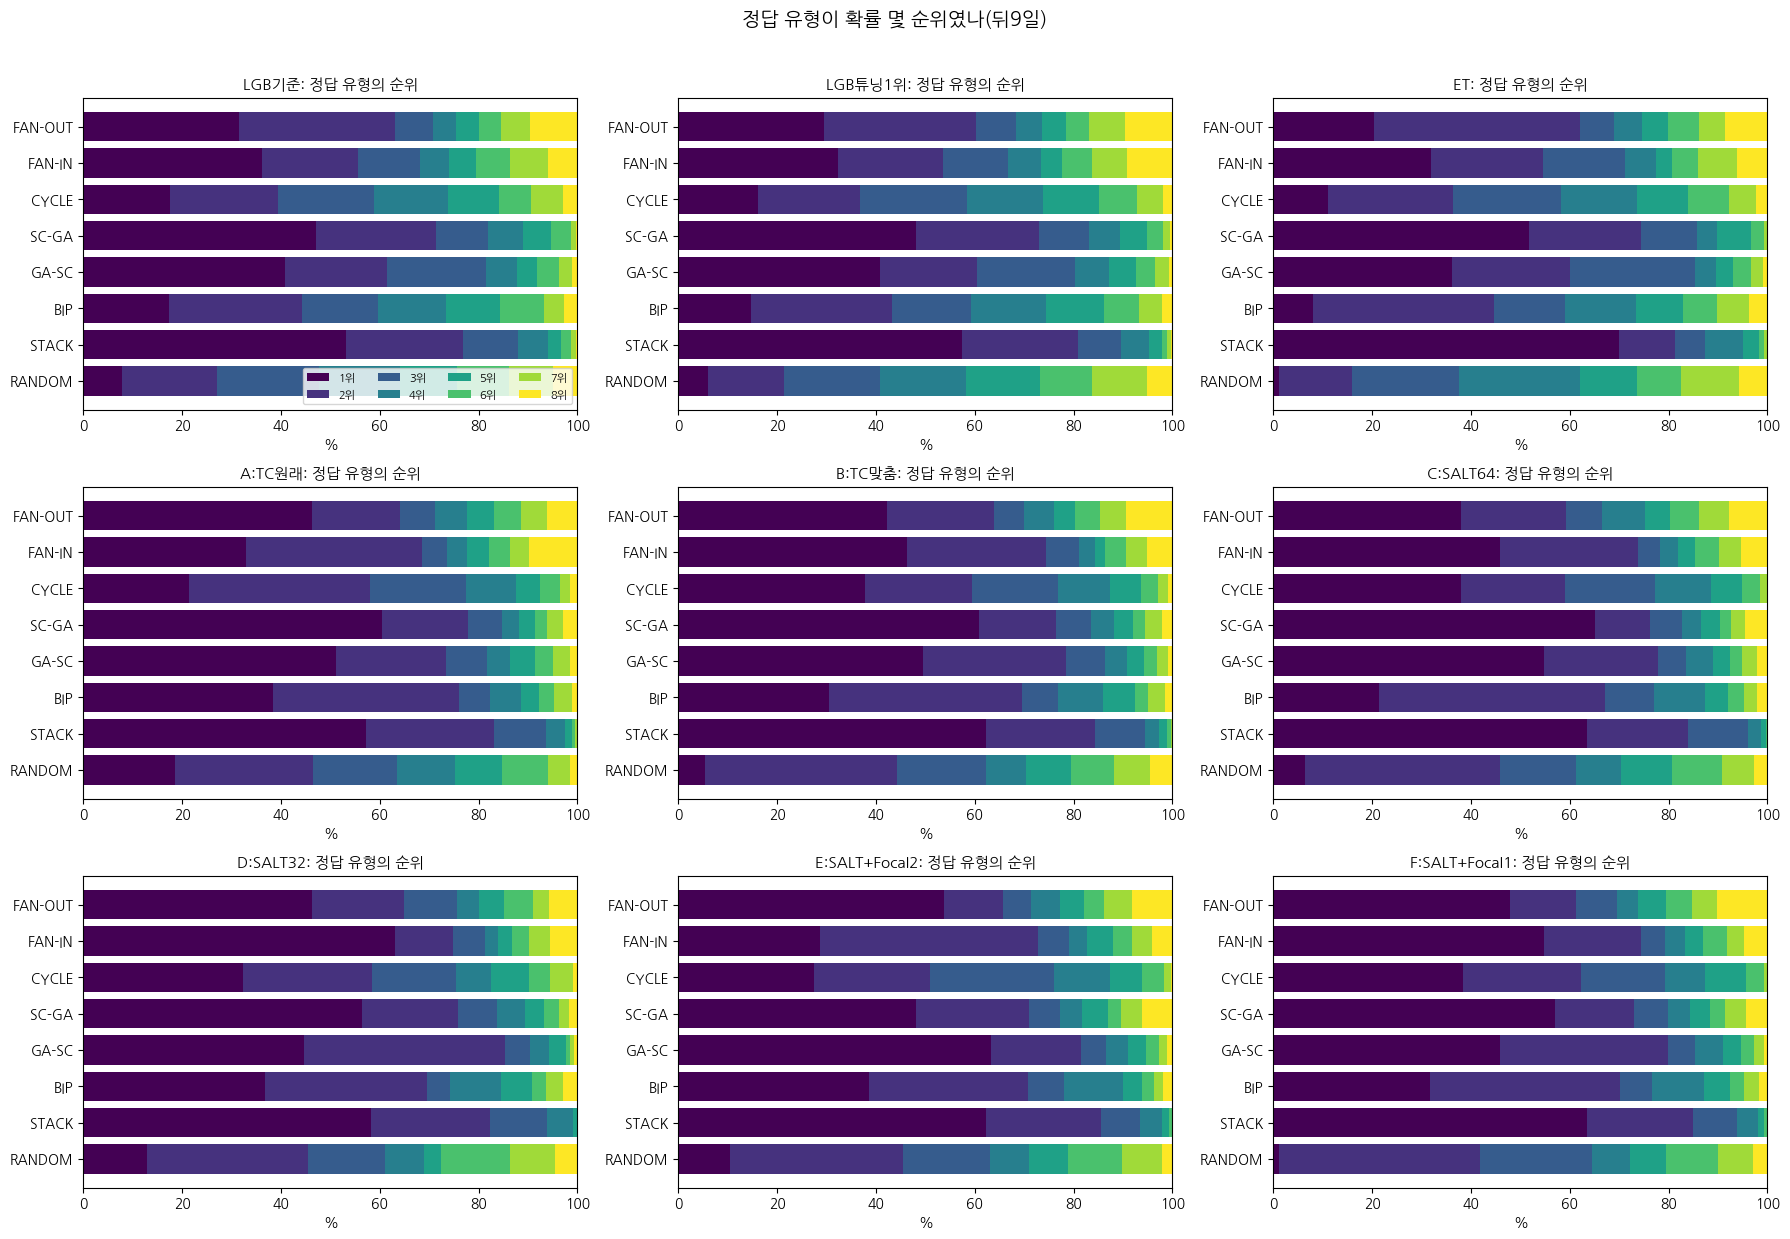

**top1**(정답이 1위 안)

유형,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM
모델,,,,,,,,
LGB기준,0.315,0.361,0.175,0.472,0.409,0.173,0.532,0.078
LGB튜닝1위,0.296,0.322,0.162,0.480,0.408,0.147,0.574,0.060
ET,0.204,0.320,0.111,0.518,0.361,0.080,0.701,0.012
A:TC원래,0.462,0.330,0.215,0.606,0.511,0.384,0.573,0.186
B:TC맞춤,0.422,0.463,0.379,0.609,0.495,0.306,0.623,0.054
C:SALT64,0.380,0.459,0.380,0.652,0.548,0.214,0.634,0.063
D:SALT32,0.463,0.631,0.324,0.564,0.448,0.368,0.582,0.130
E:SALT+Focal2,0.537,0.287,0.274,0.482,0.632,0.385,0.623,0.104
F:SALT+Focal1,0.480,0.548,0.384,0.571,0.459,0.318,0.634,0.012


**top2**(정답이 2위 안)

유형,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM
모델,,,,,,,,
LGB기준,0.631,0.556,0.394,0.714,0.614,0.442,0.768,0.271
LGB튜닝1위,0.602,0.537,0.368,0.730,0.605,0.434,0.808,0.213
ET,0.621,0.546,0.363,0.743,0.601,0.446,0.812,0.160
A:TC원래,0.640,0.685,0.581,0.778,0.734,0.760,0.831,0.466
B:TC맞춤,0.640,0.743,0.594,0.765,0.785,0.696,0.843,0.443
C:SALT64,0.593,0.738,0.591,0.762,0.778,0.672,0.840,0.459
D:SALT32,0.649,0.748,0.584,0.759,0.853,0.695,0.822,0.456
E:SALT+Focal2,0.658,0.728,0.509,0.709,0.814,0.709,0.855,0.454
F:SALT+Focal1,0.613,0.744,0.623,0.729,0.799,0.702,0.849,0.418


**top3**(정답이 3위 안)

유형,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM
모델,,,,,,,,
LGB기준,0.708,0.681,0.589,0.819,0.815,0.596,0.880,0.478
LGB튜닝1위,0.683,0.667,0.584,0.830,0.803,0.592,0.897,0.408
ET,0.689,0.711,0.583,0.857,0.853,0.591,0.875,0.377
A:TC원래,0.712,0.736,0.776,0.847,0.817,0.822,0.936,0.636
B:TC맞춤,0.700,0.811,0.768,0.836,0.864,0.768,0.944,0.623
C:SALT64,0.665,0.783,0.773,0.827,0.834,0.770,0.960,0.612
D:SALT32,0.757,0.814,0.753,0.838,0.904,0.742,0.938,0.611
E:SALT+Focal2,0.713,0.792,0.760,0.773,0.866,0.781,0.935,0.631
F:SALT+Focal1,0.695,0.792,0.792,0.798,0.854,0.766,0.939,0.644


In [11]:
def rank_true(P, t):
    return (P > P[np.arange(len(t)), t][:, None]).sum(1) + 1           # 정답 확률보다 큰 유형 수 + 1
TOPK = []
fig, ax = grid(len(PROB), ncol=3, w=6.0, h=4.2)
for a, m in zip(ax, PROB):
    rk = rank_true(M[m]['P'], y); D = np.zeros((K, K))
    for k in range(K):
        D[k] = np.bincount(rk[y == k] - 1, minlength=K) / max((y == k).sum(), 1)
    bottom = np.zeros(K); cols = plt.cm.viridis(np.linspace(0, 1, K))
    for r_ in range(K):
        a.barh(SHORT, D[:, r_] * 100, left=bottom * 100, color=cols[r_], label=f'{r_ + 1}위'); bottom += D[:, r_]
    a.set_title(f'{m}: 정답 유형의 순위', fontsize=11); a.set_xlim(0, 100); a.invert_yaxis(); a.set_xlabel('%')
    TOPK.append(pd.DataFrame({'모델': m, '유형': CN, 'top1': D[:, 0], 'top2': D[:, :2].sum(1), 'top3': D[:, :3].sum(1)}))
ax[0].legend(ncol=4, fontsize=8, loc='lower right'); plt.suptitle(f'정답 유형이 확률 몇 순위였나({PERIOD})', fontsize=14); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()
TK = pd.concat(TOPK)
for col in ('top1', 'top2', 'top3'):
    display(Markdown(f'**{col}**(정답이 {col[-1]}위 안)')); display(TK.pivot(index='모델', columns='유형', values=col)[CN].loc[PROB].style.background_gradient(cmap='Greens', axis=None).format('{:.3f}'))

## 8. 확신도 — 맞은 것 · 틀린 것의 확률
- **8-1**: 유형별로 **정답 유형에 준 확률** 분포(맞은 행 / 틀린 행). 틀린 행에서도 정답 확률이 높으면 근소하게 진 것.
- **8-2**: 1등 확률 구간별 실제 정답률(신뢰도 그림). 대각선에 가까울수록 확률을 믿을 만하다.

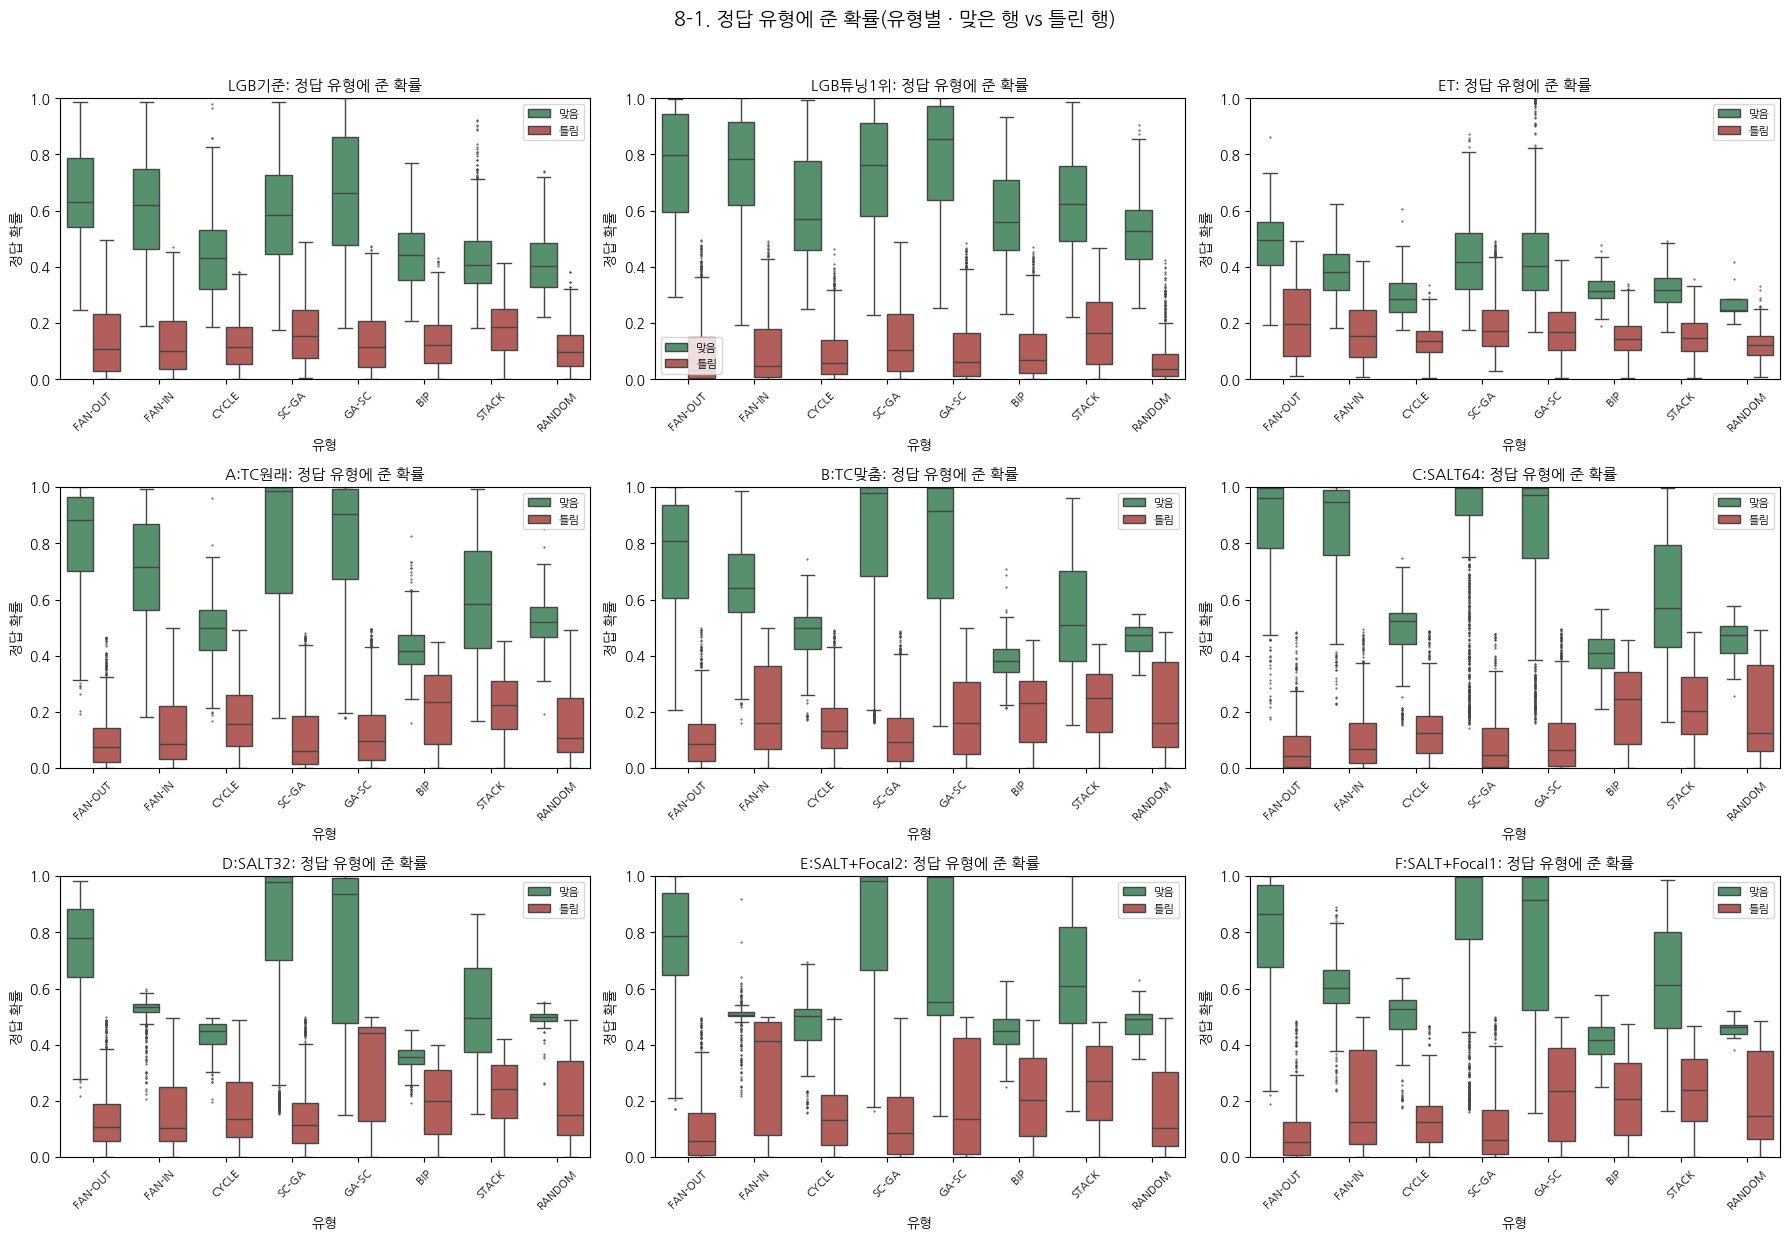

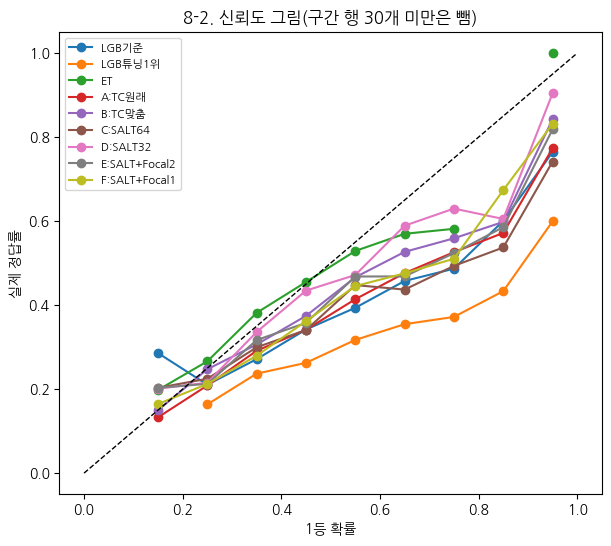

**1등 확률 구간별 정답률**

,0.0~0.1,0.1~0.2,0.2~0.3,0.3~0.4,0.4~0.5,0.5~0.6,0.6~0.7,0.7~0.8,0.8~0.9,0.9~1.0
LGB기준,NaN,0.286,0.210,0.271,0.342,0.394,0.457,0.487,0.601,0.764
LGB튜닝1위,NaN,NaN,0.164,0.237,0.263,0.317,0.355,0.372,0.433,0.599
ET,NaN,0.198,0.266,0.382,0.455,0.529,0.570,0.582,NaN,1.000
A:TC원래,NaN,0.133,0.209,0.291,0.341,0.414,0.476,0.526,0.572,0.774
B:TC맞춤,NaN,0.150,0.247,0.306,0.374,0.466,0.527,0.559,0.598,0.842
C:SALT64,NaN,0.203,0.225,0.300,0.341,0.448,0.437,0.493,0.537,0.742
D:SALT32,NaN,0.201,0.215,0.336,0.434,0.472,0.589,0.630,0.605,0.904
E:SALT+Focal2,NaN,0.203,0.212,0.317,0.358,0.468,0.468,0.524,0.586,0.818
F:SALT+Focal1,NaN,0.165,0.212,0.280,0.362,0.445,0.476,0.510,0.674,0.831


In [12]:
fig, ax = grid(len(PROB), ncol=3, w=6.0, h=4.2)
for a, m in zip(ax, PROB):
    P = M[m]['P']; pt = P[np.arange(len(y)), y]; ok = M[m]['pred'] == y
    df = pd.DataFrame({'유형': np.array(SHORT)[y], '정답 확률': pt, '결과': np.where(ok, '맞음', '틀림')})
    sns.boxplot(data=df, x='유형', y='정답 확률', hue='결과', order=SHORT, hue_order=['맞음', '틀림'], ax=a, fliersize=0.5, palette={'맞음': '#4c9a6a', '틀림': '#c0504d'})
    a.set_title(f'{m}: 정답 유형에 준 확률', fontsize=11); a.tick_params(axis='x', rotation=45, labelsize=8); a.set_ylim(0, 1); a.legend(fontsize=8)
plt.suptitle('8-1. 정답 유형에 준 확률(유형별 · 맞은 행 vs 틀린 행)', fontsize=14); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()
fig, a = plt.subplots(figsize=(7, 6)); bins = np.linspace(0, 1, 11); rel = []
for m in PROB:
    P = M[m]['P']; mx = P.max(1); ok = M[m]['pred'] == y; b = np.clip(np.digitize(mx, bins) - 1, 0, 9)
    acc = [ok[b == i].mean() if (b == i).sum() >= 30 else np.nan for i in range(10)]; cen = (bins[:-1] + bins[1:]) / 2
    a.plot(cen, acc, marker='o', label=m); rel.append(pd.Series(acc, index=[f'{bins[i]:.1f}~{bins[i + 1]:.1f}' for i in range(10)], name=m))
a.plot([0, 1], [0, 1], 'k--', lw=1); a.set_xlabel('1등 확률'); a.set_ylabel('실제 정답률'); a.set_title('8-2. 신뢰도 그림(구간 행 30개 미만은 뺌)'); a.legend(fontsize=8); plt.show()
display(Markdown('**1등 확률 구간별 정답률**')); display(pd.concat(rel, axis=1).T.round(3))

## 9. 날짜별
- **9-1**: 날짜별 정답률(모든 모델). 특정 날에만 무너지는지 본다.
- **9-2**: 모델마다 날짜 × 유형 재현율(행이 적은 칸은 흔들린다 — 칸 아래 숫자 = 그날 그 유형 행 수는 표로).

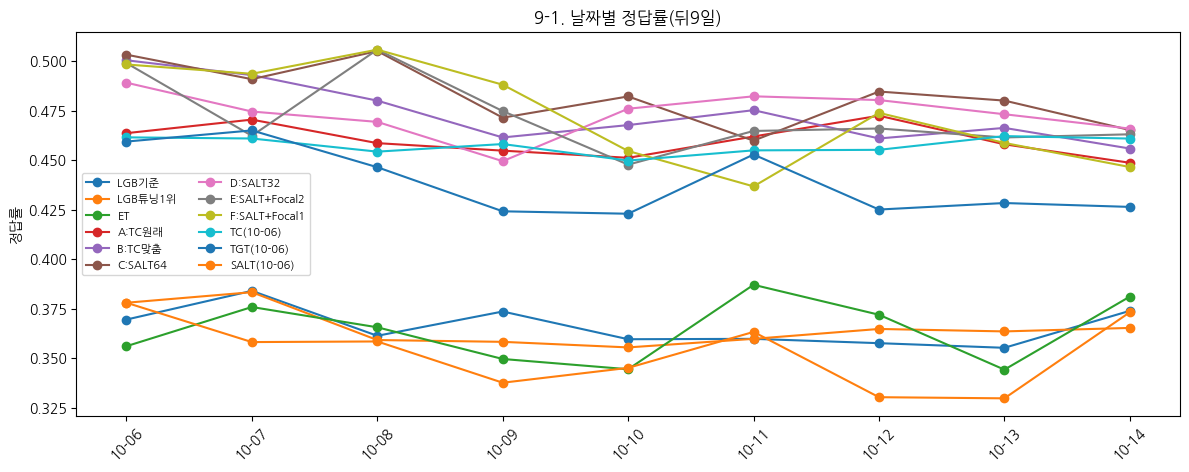

**날짜 × 유형 행 수**

,FAN-OUT,FAN-IN,CYCLE,SCATTER-GATHER,GATHER-SCATTER,BIPARTITE,STACK,RANDOM
2022-10-06,138,134,111,277,291,115,262,87
2022-10-07,131,147,131,270,303,123,281,85
2022-10-08,132,125,128,270,272,121,248,104
2022-10-09,149,127,124,292,276,137,275,124
2022-10-10,151,126,128,295,261,131,263,99
2022-10-11,149,136,114,269,270,126,266,101
2022-10-12,131,122,124,255,264,131,270,98
2022-10-13,148,135,142,282,300,118,229,98
2022-10-14,128,133,125,287,270,96,250,104


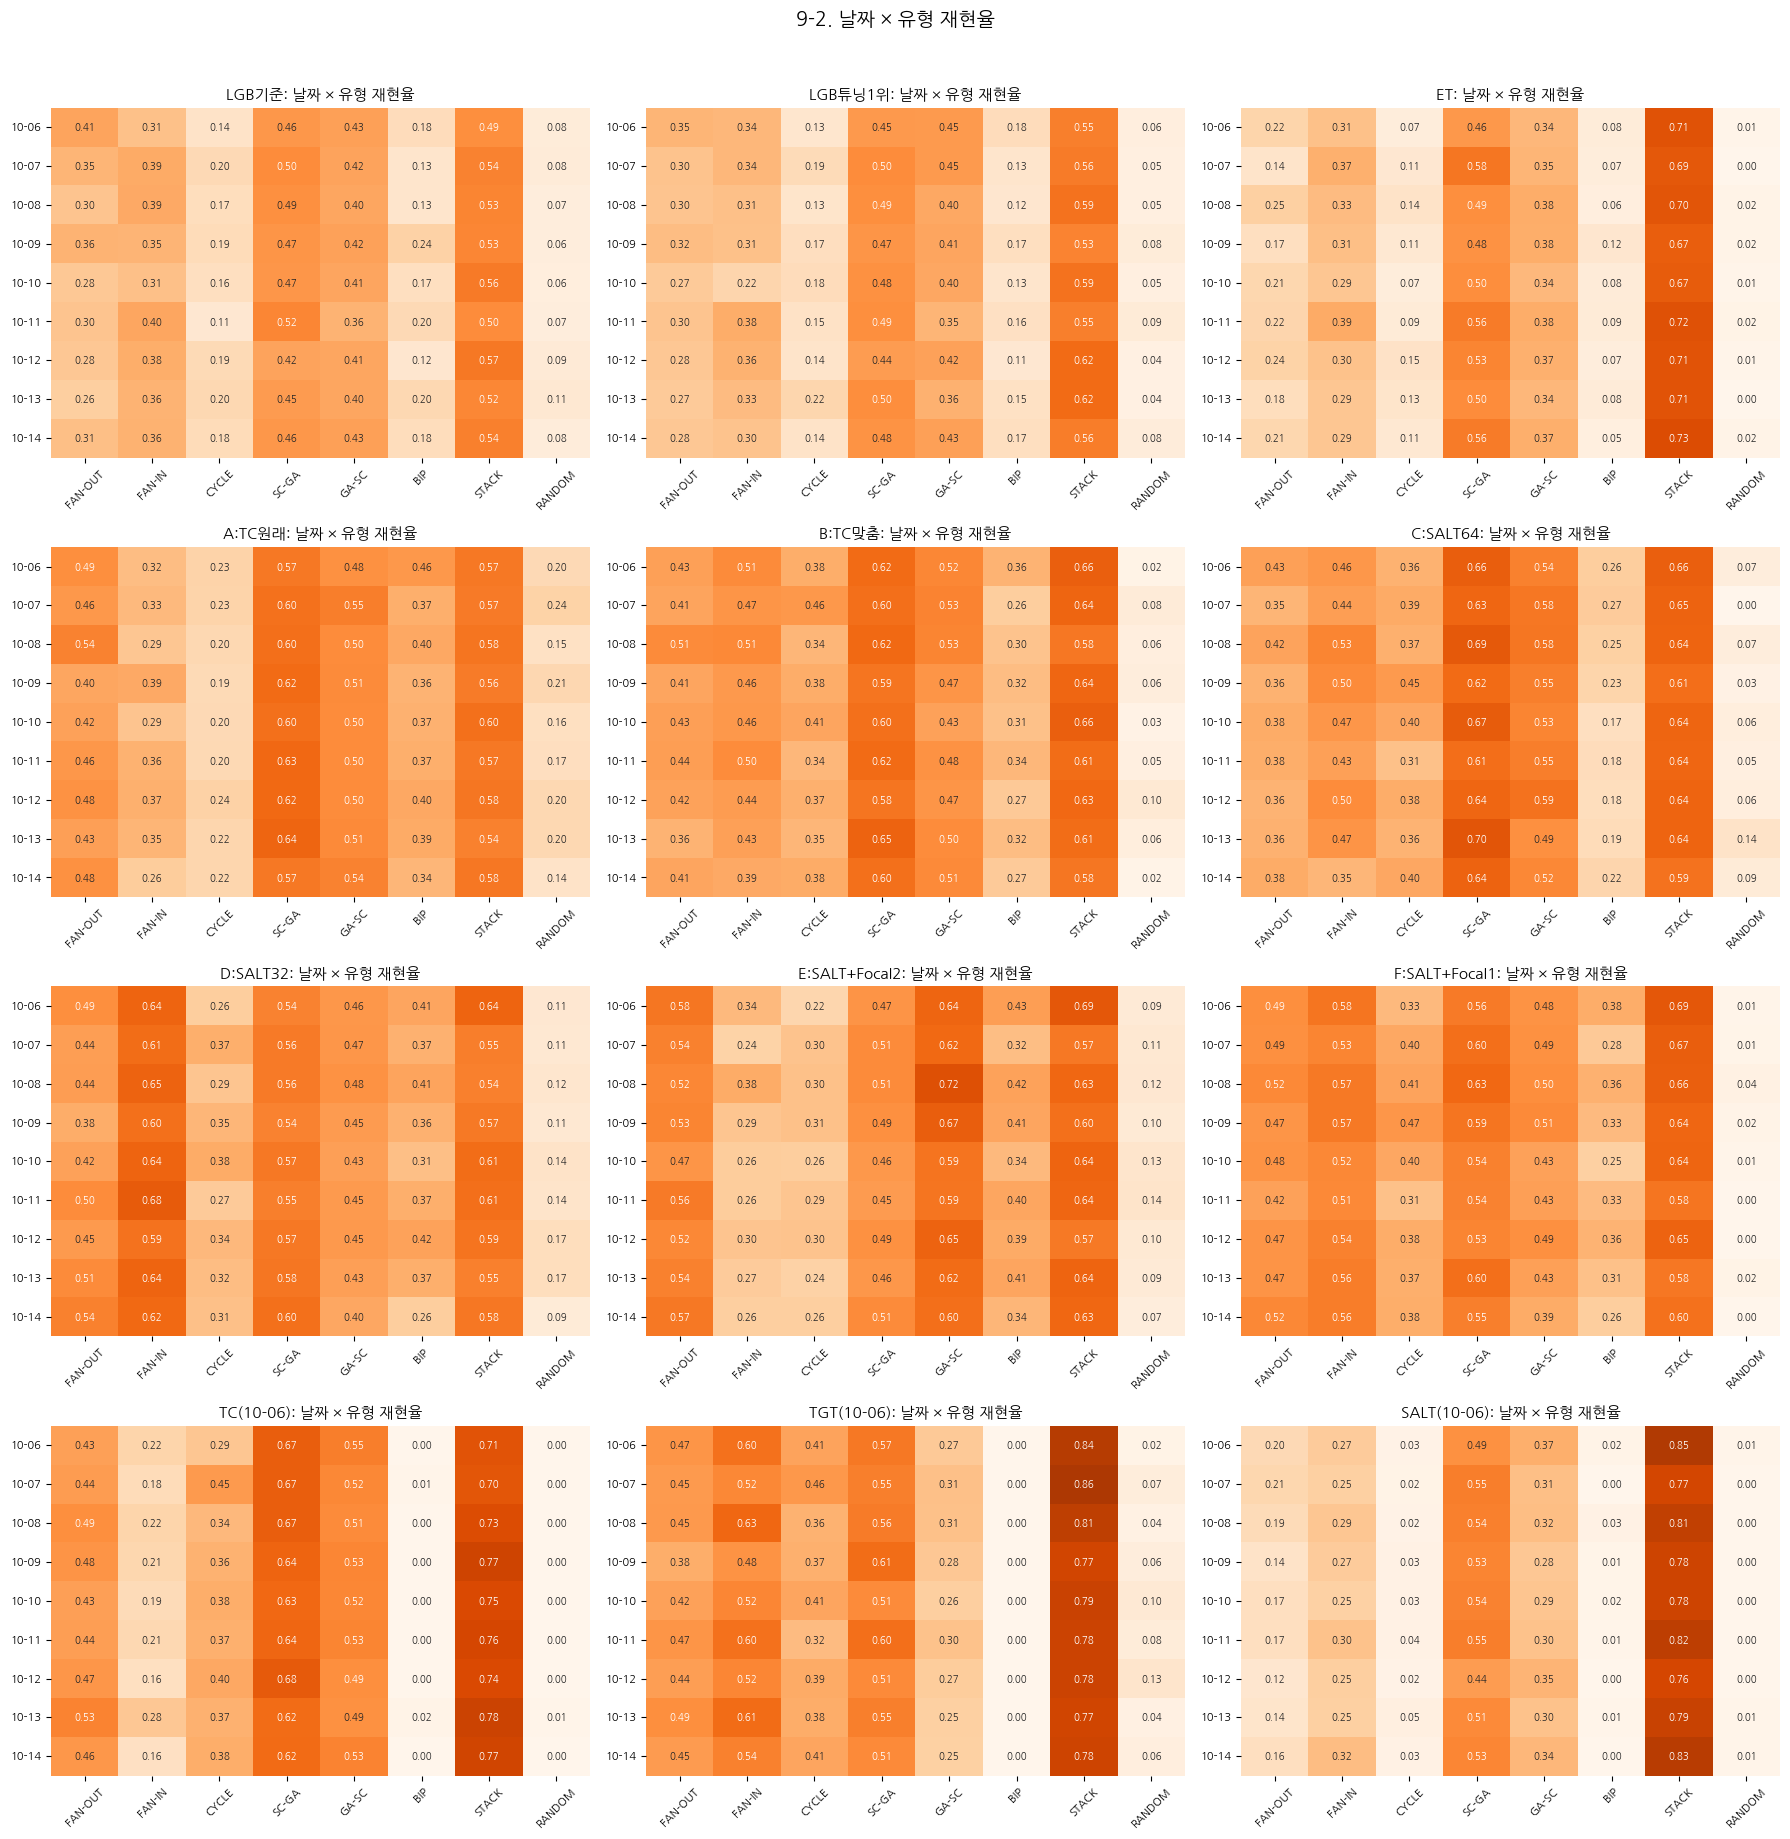

In [13]:
ud = np.unique(day); fig, a = plt.subplots(figsize=(12, 5))
for m in MODELS:
    a.plot([DAYS[d][5:] for d in ud], [(M[m]['pred'][day == d] == y[day == d]).mean() for d in ud], marker='o', label=m)
a.set_title(f'9-1. 날짜별 정답률({PERIOD})'); a.set_ylabel('정답률'); a.legend(fontsize=8, ncol=2); plt.xticks(rotation=45); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()
NDK = pd.DataFrame([[int(((day == d) & (y == k)).sum()) for k in range(K)] for d in ud], index=[DAYS[d] for d in ud], columns=CN)
display(Markdown('**날짜 × 유형 행 수**')); display(NDK)
fig, ax = grid(len(MODELS), ncol=3, w=6.0, h=0.32 * len(ud) + 1.8)
for a, m in zip(ax, MODELS):
    R = np.array([[((M[m]['pred'] == y) & (day == d) & (y == k)).sum() / max(((day == d) & (y == k)).sum(), 1) for k in range(K)] for d in ud])
    sns.heatmap(R, annot=True, fmt='.2f', cmap='Oranges', vmin=0, vmax=1, cbar=False, ax=a, annot_kws={'size': 7}, xticklabels=SHORT, yticklabels=[DAYS[d][5:] for d in ud])
    a.set_title(f'{m}: 날짜 × 유형 재현율', fontsize=11); a.tick_params(axis='x', rotation=45, labelsize=8); a.tick_params(axis='y', labelsize=8)
plt.suptitle('9-2. 날짜 × 유형 재현율', fontsize=14); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()

## 10. 본 시도 vs 처음 본 시도
**본 시도** = 이 세탁 시도(사건)의 다른 거래가 train 에도 있었던 행 · **처음 본 시도** = train 에 없던 시도의 행. 처음 본 시도는 모델이 일반화한 정도를 보여 준다.

,모델,묶음,행,정답률,macro정밀도,macro재현율,재현율_FAN-OUT,재현율_FAN-IN,재현율_CYCLE,재현율_SC-GA,재현율_GA-SC,재현율_BIP,재현율_STACK,재현율_RANDOM
0,LGB기준,본 시도,6942,0.441,0.379,0.370,0.442,0.507,0.213,0.515,0.466,0.169,0.559,0.088
1,LGB기준,처음 본 시도,5973,0.279,0.243,0.232,0.162,0.155,0.132,0.414,0.247,0.174,0.507,0.069
2,LGB튜닝1위,본 시도,6942,0.443,0.380,0.364,0.430,0.468,0.187,0.517,0.477,0.152,0.608,0.071
3,LGB튜닝1위,처음 본 시도,5973,0.275,0.232,0.221,0.134,0.116,0.135,0.431,0.215,0.146,0.544,0.051
4,ET,본 시도,6942,0.420,0.368,0.324,0.275,0.419,0.126,0.543,0.411,0.073,0.734,0.010
5,ET,처음 본 시도,5973,0.299,0.263,0.233,0.118,0.179,0.094,0.484,0.222,0.082,0.671,0.014
6,A:TC원래,본 시도,6942,0.579,0.502,0.508,0.635,0.431,0.269,0.781,0.577,0.433,0.697,0.240
7,A:TC원래,처음 본 시도,5973,0.321,0.327,0.284,0.253,0.187,0.154,0.369,0.328,0.375,0.464,0.141
8,B:TC맞춤,본 시도,6942,0.597,0.525,0.516,0.613,0.548,0.499,0.751,0.578,0.320,0.740,0.081
9,B:TC맞춤,처음 본 시도,5973,0.329,0.330,0.289,0.192,0.344,0.244,0.416,0.263,0.303,0.521,0.033


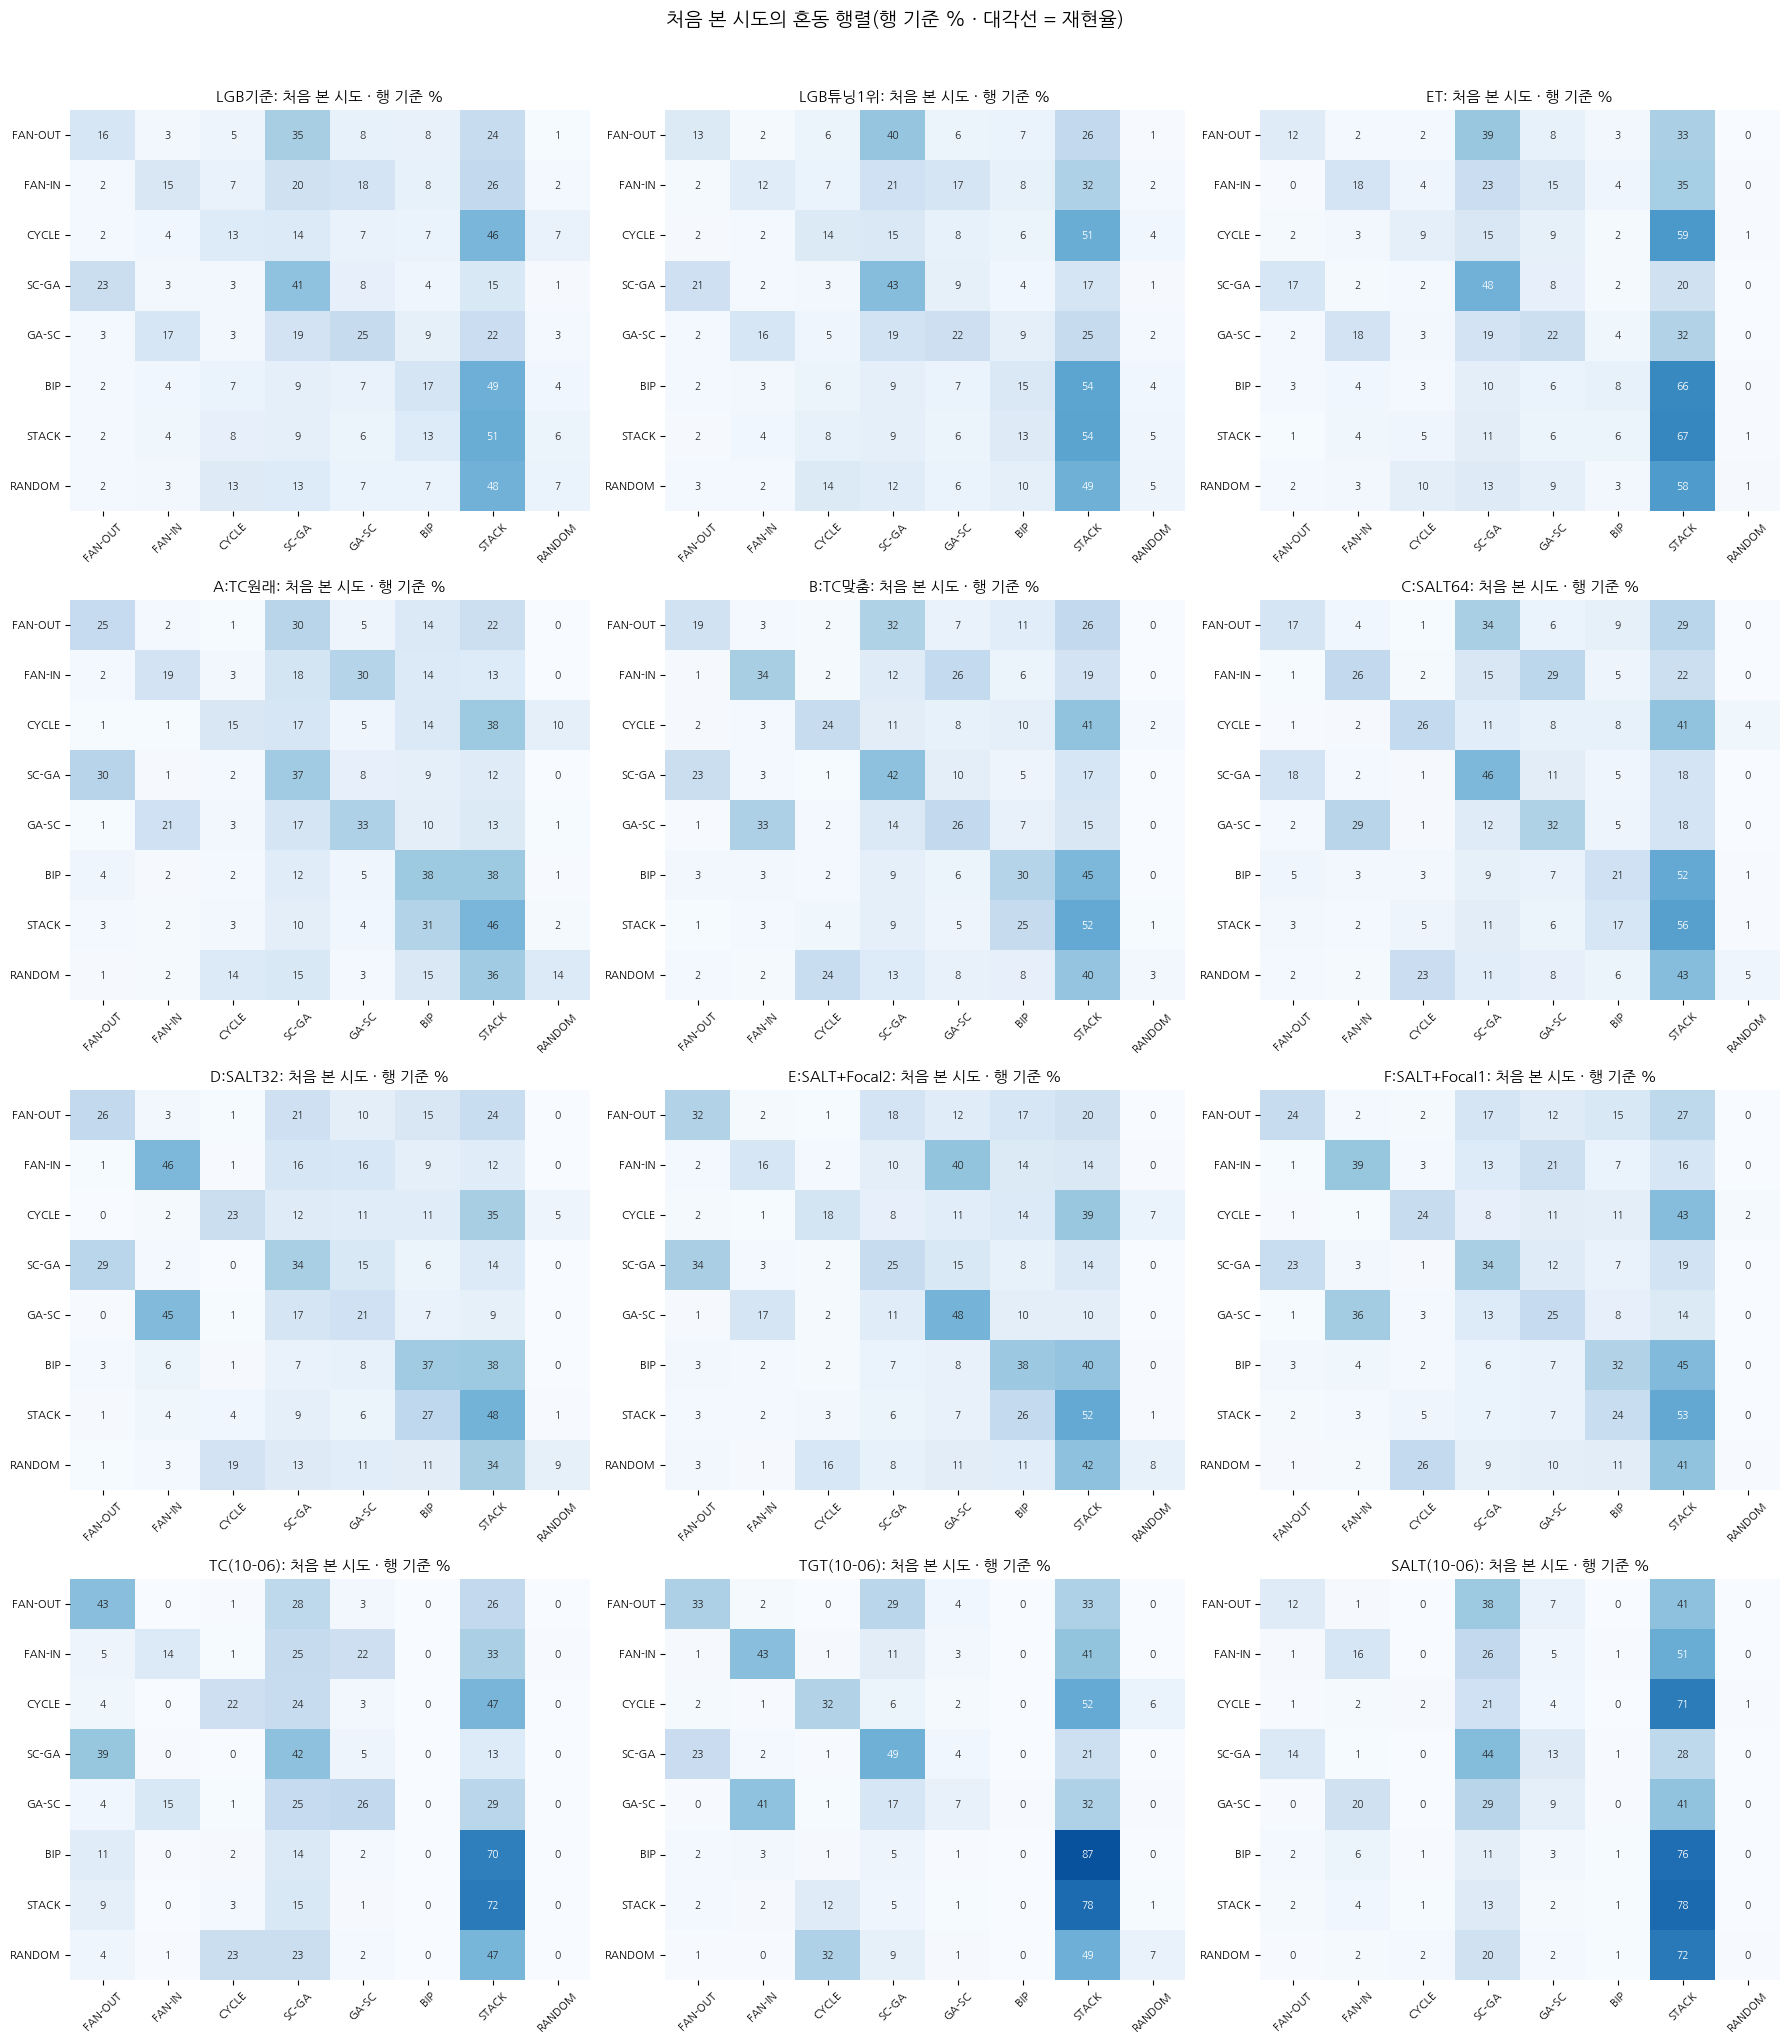

In [14]:
rows = []
for m in MODELS:
    for g, sm in (('본 시도', seen), ('처음 본 시도', ~seen)):
        c = cm_of(y[sm], M[m]['pred'][sm]); p, r, _ = pr_of(c)
        rows.append(dict(모델=m, 묶음=g, 행=int(sm.sum()), 정답률=np.trace(c) / max(c.sum(), 1), macro정밀도=p.mean(), macro재현율=r.mean(), **{f'재현율_{SHORT[k]}': r[k] for k in range(K)}))
SEEN = pd.DataFrame(rows); display(SEEN.round(3))
fig, ax = grid(len(MODELS))
for a, m in zip(ax, MODELS):
    c = cm_of(y[~seen], M[m]['pred'][~seen]).astype(float); X = c / np.maximum(c.sum(1, keepdims=True), 1)
    sns.heatmap(X * 100, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar=False, ax=a, annot_kws={'size': 7.5}, xticklabels=SHORT, yticklabels=SHORT)
    a.set_title(f'{m}: 처음 본 시도 · 행 기준 %', fontsize=11); a.tick_params(axis='x', rotation=45, labelsize=8); a.tick_params(axis='y', rotation=0, labelsize=8)
plt.suptitle('처음 본 시도의 혼동 행렬(행 기준 % · 대각선 = 재현율)', fontsize=14); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()

## 11. 사건(시도) 단위
같은 시도(attempt)의 거래 판정을 다수결로 묶어 **시도 하나 = 판정 하나**로 본다(동점이면 확률 합이 큰 유형 — lib8.Scorer 와 같은 규칙. 예측만 있는 모델은 표 수). 구간 안의 거래만 쓴다.

,시도,정답률,macro정밀도,macro재현율
모델,,,,
LGB기준,5013,0.340,0.341,0.311
LGB튜닝1위,5013,0.333,0.330,0.298
ET,5013,0.316,0.312,0.278
A:TC원래,5013,0.419,0.431,0.396
B:TC맞춤,5013,0.428,0.436,0.396
C:SALT64,5013,0.443,0.466,0.400
D:SALT32,5013,0.434,0.442,0.413
E:SALT+Focal2,5013,0.429,0.442,0.393
F:SALT+Focal1,5013,0.426,0.433,0.398


시도 크기(구간 안 거래 수): 중앙값 2 · 평균 2.6 · 최대 15 · 1건짜리 시도 40.2%

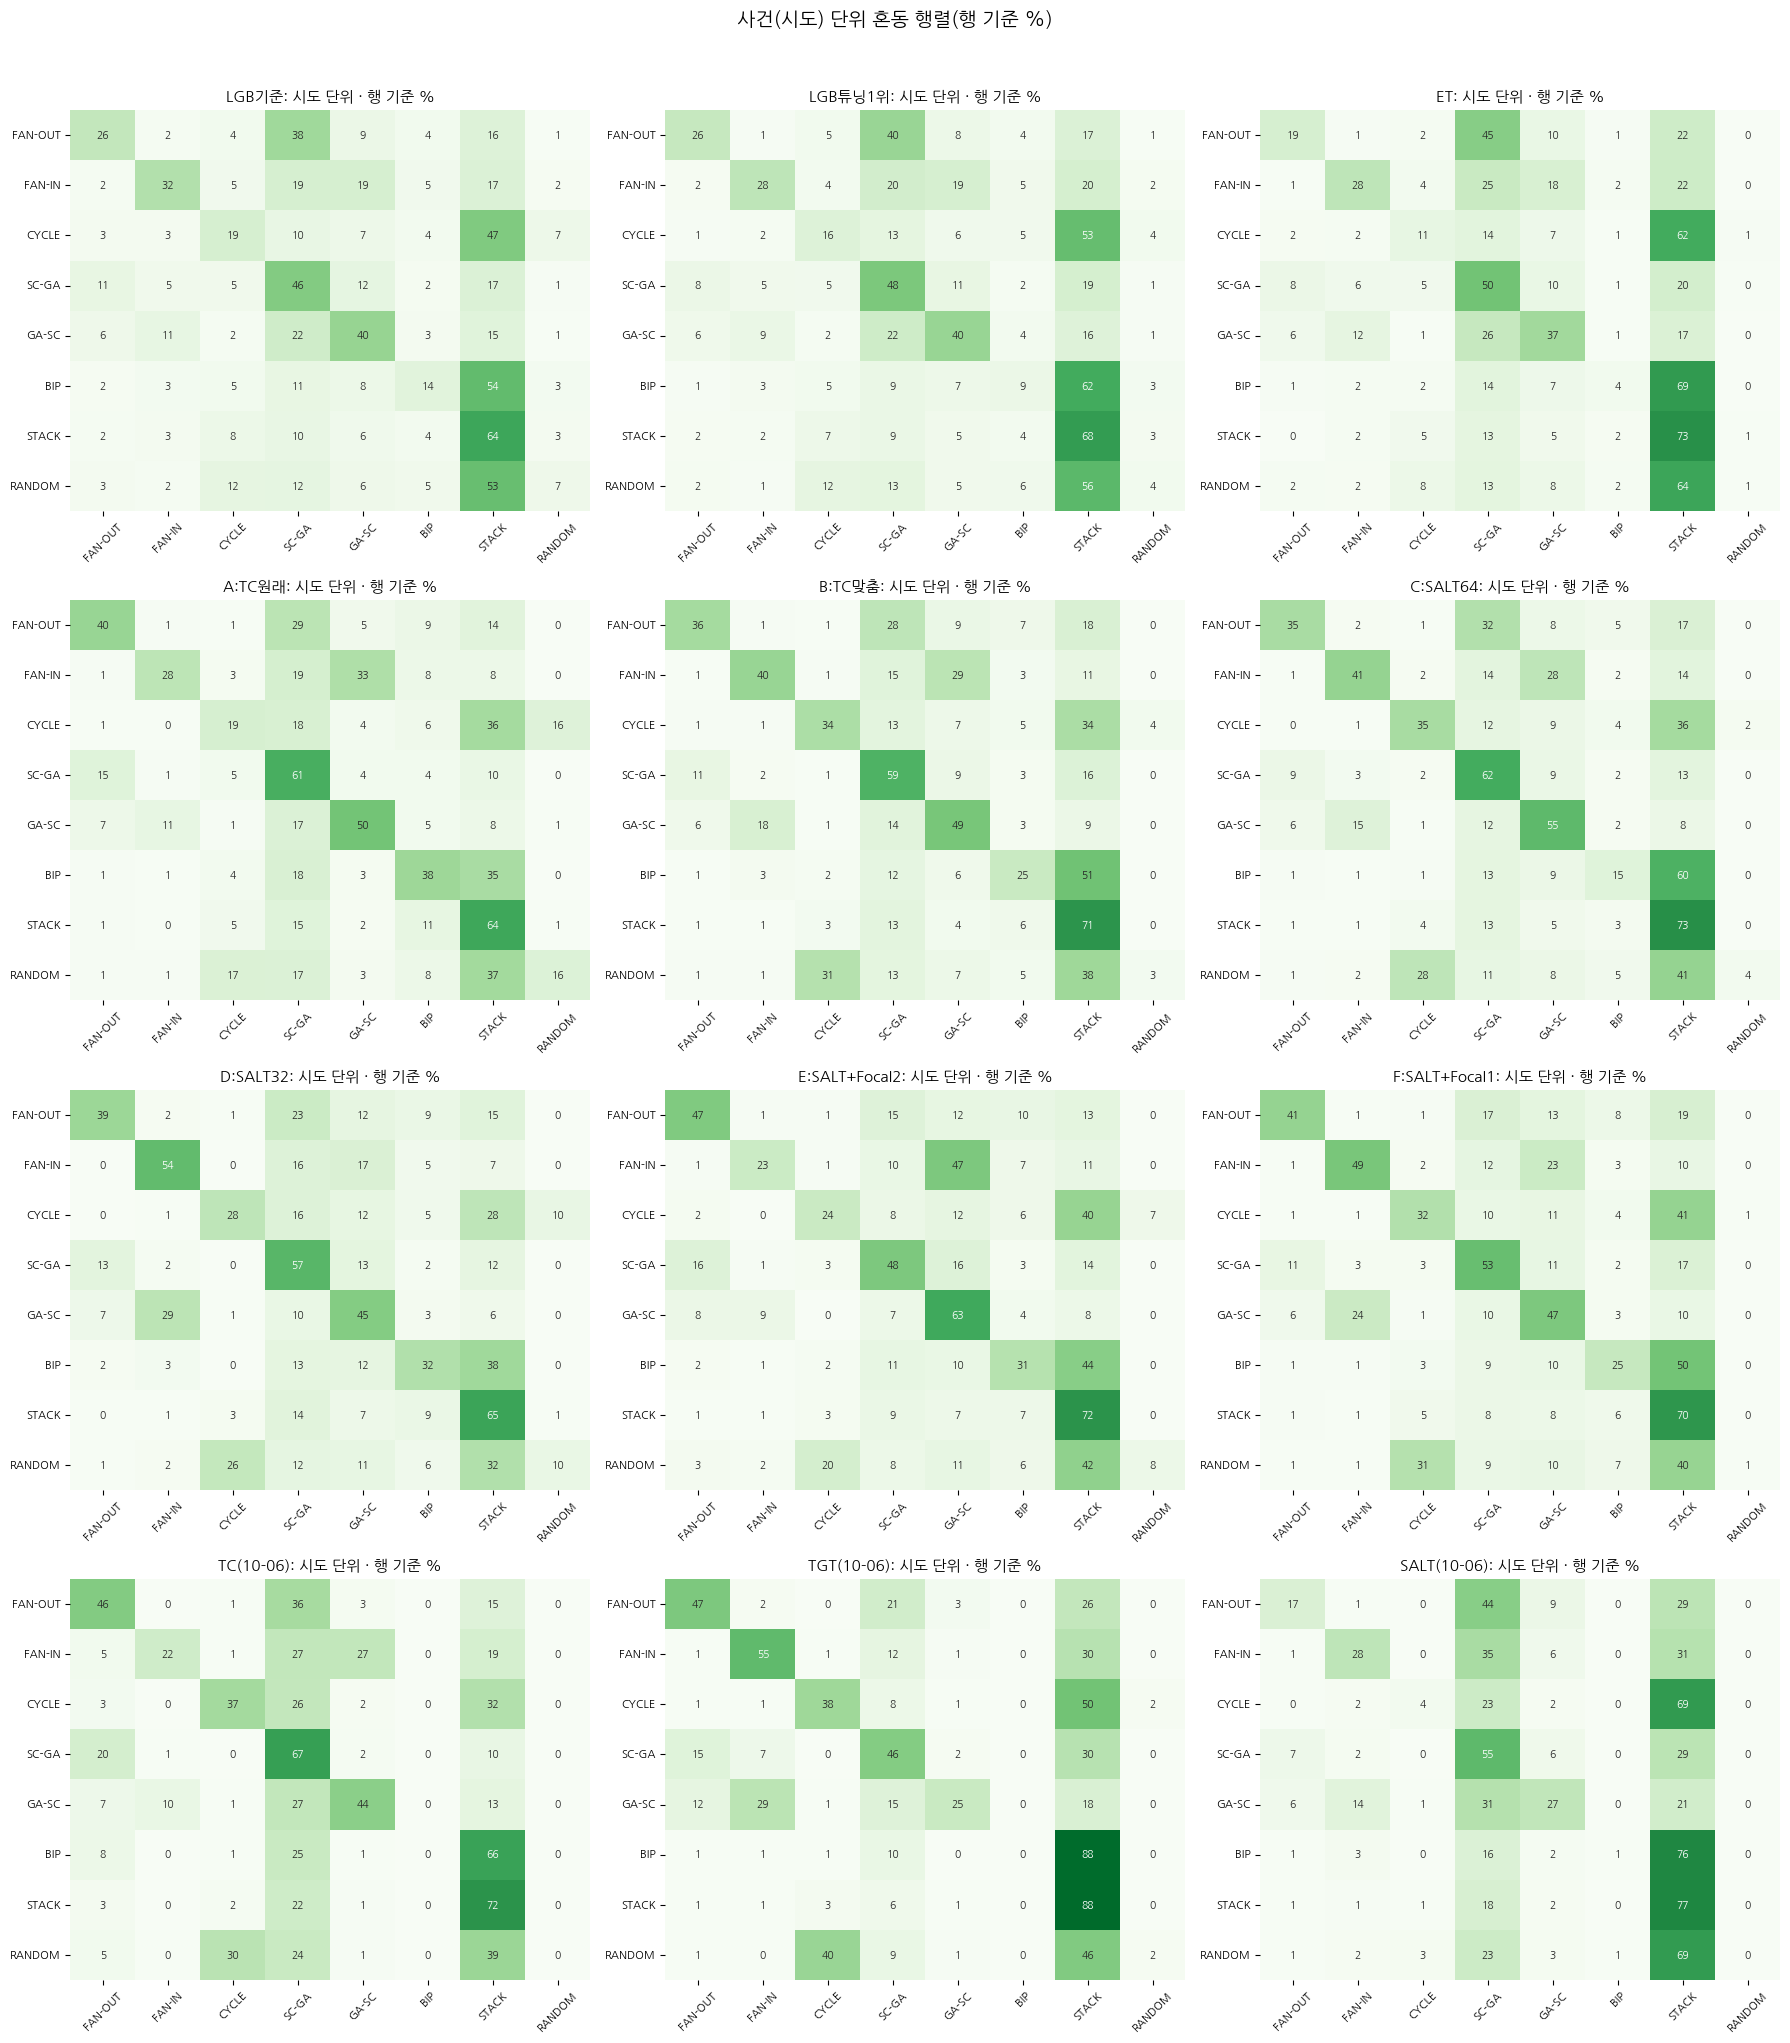

In [15]:
ua, ainv = np.unique(att, return_inverse=True); ay = np.zeros(len(ua), np.int64); ay[ainv] = y; asz = np.bincount(ainv)
def vote(m):
    pred = M[m]['pred']; votes = np.zeros((len(ua), K)); np.add.at(votes, (ainv, pred), 1)
    ps = np.zeros((len(ua), K)); np.add.at(ps, ainv, M[m]['P'] if M[m]['P'] is not None else np.eye(K)[pred])
    return (votes * 1e6 + ps).argmax(1)
AV = {m: vote(m) for m in MODELS}; rows = []
for m in MODELS:
    c = cm_of(ay, AV[m]); p, r, _ = pr_of(c); rows.append(dict(모델=m, 시도=len(ua), 정답률=np.trace(c) / c.sum(), macro정밀도=p.mean(), macro재현율=r.mean()))
display(pd.DataFrame(rows).set_index('모델').round(3))
display(Markdown(f'시도 크기(구간 안 거래 수): 중앙값 {np.median(asz):.0f} · 평균 {asz.mean():.1f} · 최대 {asz.max()} · 1건짜리 시도 {(asz == 1).mean() * 100:.1f}%'))
fig, ax = grid(len(MODELS))
for a, m in zip(ax, MODELS):
    c = cm_of(ay, AV[m]).astype(float); X = c / np.maximum(c.sum(1, keepdims=True), 1)
    sns.heatmap(X * 100, annot=True, fmt='.0f', cmap='Greens', vmin=0, vmax=100, cbar=False, ax=a, annot_kws={'size': 7.5}, xticklabels=SHORT, yticklabels=SHORT)
    a.set_title(f'{m}: 시도 단위 · 행 기준 %', fontsize=11); a.tick_params(axis='x', rotation=45, labelsize=8); a.tick_params(axis='y', rotation=0, labelsize=8)
plt.suptitle('사건(시도) 단위 혼동 행렬(행 기준 %)', fontsize=14); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()

## 12. 두 모델 비교 · 모델끼리 같은 예측 비율
- **12-1**: `A_MODEL` 과 `B_MODEL` 을 유형별로 — 둘 다 맞음 / A 만 맞음 / B 만 맞음 / 둘 다 틀림.
- **12-2**: 실제 유형마다 A 의 예측(행) × B 의 예측(열) 개수 — 두 모델이 어디서 갈리는지.
- **12-3**: 모든 모델 쌍의 같은 예측 비율(높을수록 비슷하게 찍음 · 섞기 짝을 고를 때 참고).

,둘 다 맞음,D:SALT32 만 맞음,LGB기준 만 맞음,둘 다 틀림,합
FAN-OUT,267,315,129,546,1257
FAN-IN,355,393,73,364,1185
CYCLE,79,286,118,644,1127
SCATTER-GATHER,786,623,392,696,2497
GATHER-SCATTER,556,566,469,916,2507
BIPARTITE,89,315,101,593,1098
STACK,823,541,423,557,2344
RANDOM,12,105,58,725,900


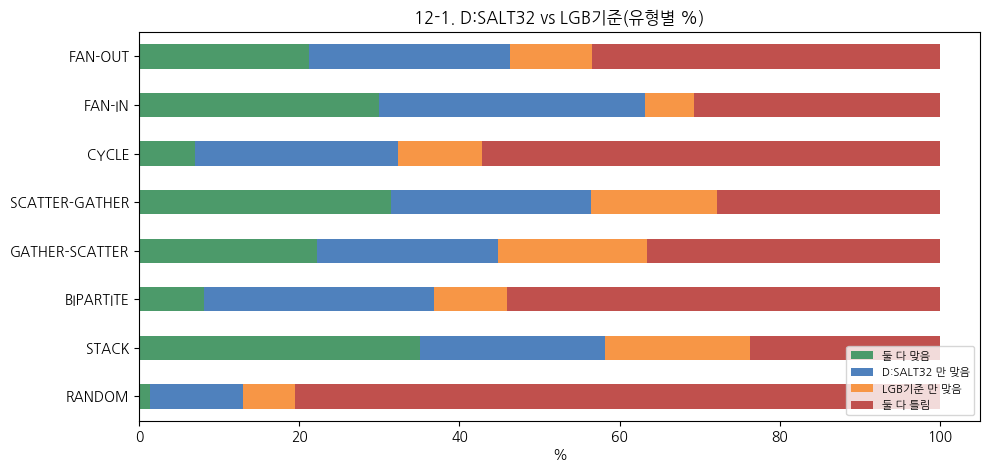

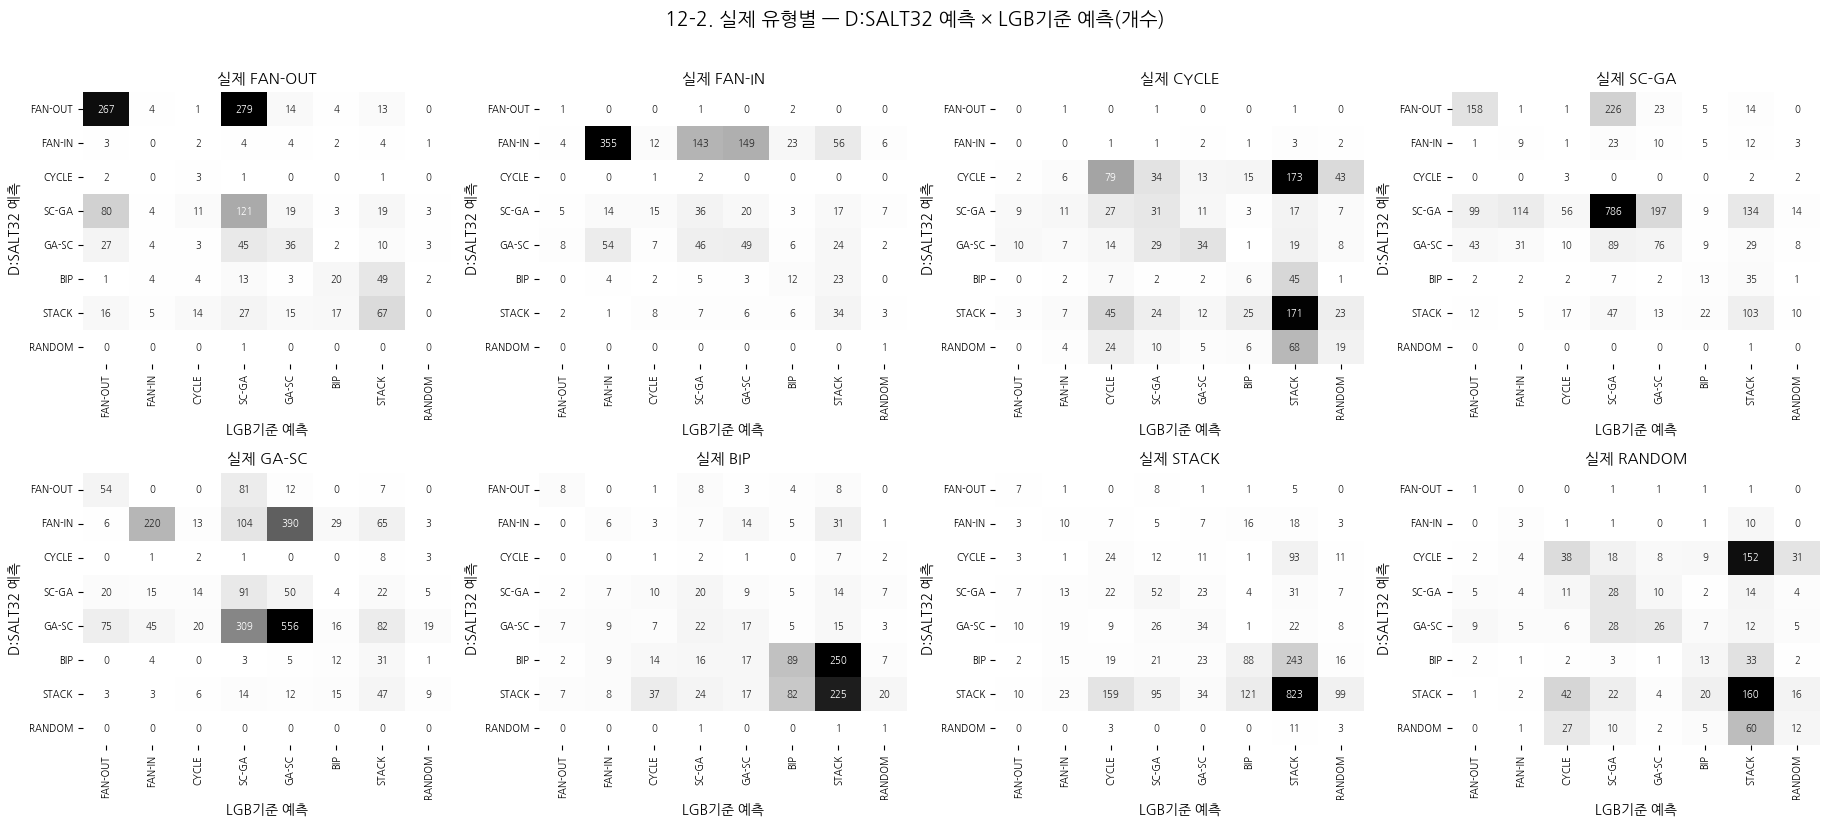

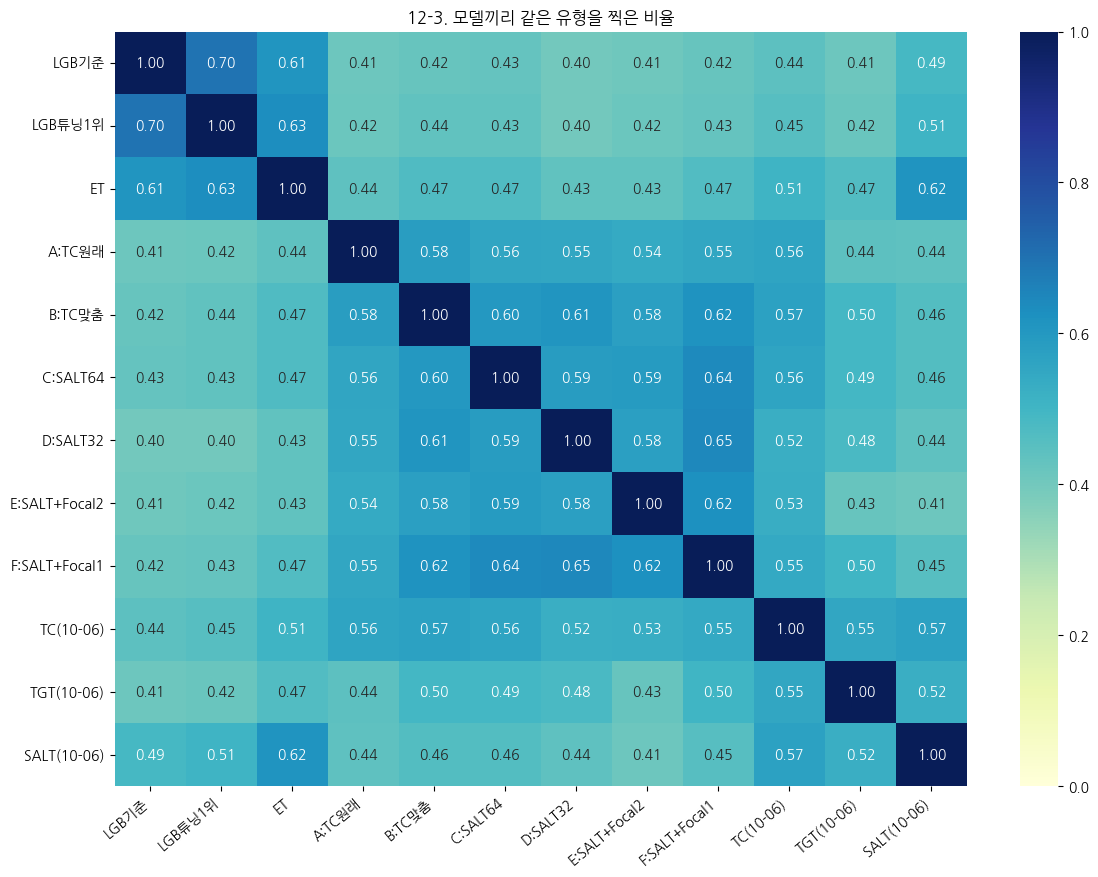

In [16]:
A_MODEL = 'D:SALT32' if 'D:SALT32' in M else MODELS[-1]
B_MODEL = 'LGB기준' if 'LGB기준' in M else MODELS[0]
a_ok, b_ok = M[A_MODEL]['pred'] == y, M[B_MODEL]['pred'] == y
T = pd.DataFrame({'둘 다 맞음': [((a_ok & b_ok) & (y == k)).sum() for k in range(K)], f'{A_MODEL} 만 맞음': [((a_ok & ~b_ok) & (y == k)).sum() for k in range(K)],
                  f'{B_MODEL} 만 맞음': [((~a_ok & b_ok) & (y == k)).sum() for k in range(K)], '둘 다 틀림': [((~a_ok & ~b_ok) & (y == k)).sum() for k in range(K)]}, index=CN)
display(T.assign(합=T.sum(1)))
(T.div(T.sum(1), axis=0) * 100).plot(kind='barh', stacked=True, figsize=(10, 5), color=['#4c9a6a', '#4f81bd', '#f79646', '#c0504d'])
plt.title(f'12-1. {A_MODEL} vs {B_MODEL}(유형별 %)'); plt.xlabel('%'); plt.gca().invert_yaxis(); plt.legend(fontsize=8, loc='lower right'); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()
fig, ax = grid(K, ncol=4, w=4.6, h=4.2)
for k, a in enumerate(ax[:K]):
    c = cm_of(M[A_MODEL]['pred'][y == k], M[B_MODEL]['pred'][y == k])
    sns.heatmap(c, annot=True, fmt='d', cmap='Greys', cbar=False, ax=a, annot_kws={'size': 7}, xticklabels=SHORT, yticklabels=SHORT)
    a.set_title(f'실제 {SHORT[k]}', fontsize=11); a.set_ylabel(f'{A_MODEL} 예측'); a.set_xlabel(f'{B_MODEL} 예측'); a.tick_params(labelsize=7)
plt.suptitle(f'12-2. 실제 유형별 — {A_MODEL} 예측 × {B_MODEL} 예측(개수)', fontsize=14); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()
AG = pd.DataFrame([[float((M[a]['pred'] == M[b]['pred']).mean()) for b in MODELS] for a in MODELS], index=MODELS, columns=MODELS)
fig, a = plt.subplots(figsize=(0.75 * len(MODELS) + 3, 0.6 * len(MODELS) + 2)); sns.heatmap(AG, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=a)
a.set_title('12-3. 모델끼리 같은 유형을 찍은 비율'); plt.xticks(rotation=40, ha='right'); plt.tight_layout(rect=[0, 0, 1, 0.965]); plt.show()

## 13. 개별 거래 목록
`rows(모델, 실제=None, 찍은=None, n=30, 정렬='p_찍은')` 로 원하는 칸의 거래를 뽑아 본다(유형 이름 또는 번호). 아래 예: 각 모델의 가장 많이 헷갈린 쌍 3개에서 확신이 큰 순서로 10건씩.
열: 거래 번호 · 날짜 · 시도 번호 · 본/처음 · 실제 · 찍은 · 정답 확률 · 찍은 유형 확률 · 1~3순위(유형:확률).

In [17]:
def _k(x):
    return x if (x is None or isinstance(x, (int, np.integer))) else CN.index(x)
def rows(model, 실제=None, 찍은=None, n=30, 정렬='p_찍은'):
    t, p = _k(실제), _k(찍은); pred = M[model]['pred']; sel = np.ones(len(y), bool)
    if t is not None: sel &= y == t
    if p is not None: sel &= pred == p
    idx = np.flatnonzero(sel); P = M[model]['P']
    df = pd.DataFrame({'거래번호': eid[idx], '날짜': [DAYS[d] for d in day[idx]], '시도번호': att[idx], '본_처음': np.where(seen[idx], '본', '처음'),
                       '실제': np.array(CN)[y[idx]], '찍은': np.array(CN)[pred[idx]]})
    if P is not None:
        df['p_정답'] = P[idx, y[idx]]; df['p_찍은'] = P[idx, pred[idx]]; o = np.argsort(-P[idx], 1)[:, :3]
        for r_ in range(3):
            df[f'{r_ + 1}순위'] = [f'{SHORT[j]}:{P[i, j]:.2f}' for i, j in zip(idx, o[:, r_])]
        df = df.sort_values(정렬, ascending=False)
    return df.head(n).reset_index(drop=True)
for m in MODELS:
    c = CM[m].copy(); np.fill_diagonal(c, 0); top = np.dstack(np.unravel_index(np.argsort(-c.ravel())[:3], c.shape))[0]
    for i, j in top:
        display(Markdown(f'**{m}** · 실제 {CN[i]} → 찍은 {CN[j]}({c[i, j]:,}행) · 확신 큰 순 10건')); display(rows(m, int(i), int(j), n=10))

**LGB기준** · 실제 GATHER-SCATTER → 찍은 SCATTER-GATHER(603행) · 확신 큰 순 10건

,거래번호,날짜,시도번호,본_처음,실제,찍은,p_정답,p_찍은,1순위,2순위,3순위
0,19128091,2022-10-11,1493,본,GATHER-SCATTER,SCATTER-GATHER,0.000381,0.989089,SC-GA:0.99,FAN-OUT:0.01,GA-SC:0.00
1,19128090,2022-10-11,1493,본,GATHER-SCATTER,SCATTER-GATHER,0.000327,0.982585,SC-GA:0.98,FAN-OUT:0.02,GA-SC:0.00
2,27082260,2022-10-09,2348,본,GATHER-SCATTER,SCATTER-GATHER,0.004206,0.982226,SC-GA:0.98,FAN-OUT:0.01,GA-SC:0.00
3,21524305,2022-10-14,1707,본,GATHER-SCATTER,SCATTER-GATHER,0.001471,0.975342,SC-GA:0.98,FAN-OUT:0.02,GA-SC:0.00
4,25377096,2022-10-11,1999,본,GATHER-SCATTER,SCATTER-GATHER,0.000280,0.972987,SC-GA:0.97,FAN-OUT:0.03,GA-SC:0.00
5,22283172,2022-10-08,1781,본,GATHER-SCATTER,SCATTER-GATHER,0.001980,0.966579,SC-GA:0.97,FAN-OUT:0.03,GA-SC:0.00
6,19128087,2022-10-10,1493,본,GATHER-SCATTER,SCATTER-GATHER,0.014178,0.962160,SC-GA:0.96,FAN-OUT:0.02,GA-SC:0.01
7,22283176,2022-10-12,1781,본,GATHER-SCATTER,SCATTER-GATHER,0.001830,0.956794,SC-GA:0.96,FAN-OUT:0.04,GA-SC:0.00
8,14337483,2022-10-12,1019,본,GATHER-SCATTER,SCATTER-GATHER,0.002987,0.956723,SC-GA:0.96,FAN-OUT:0.04,GA-SC:0.00
9,25377090,2022-10-07,1999,본,GATHER-SCATTER,SCATTER-GATHER,0.002502,0.949272,SC-GA:0.95,FAN-OUT:0.05,GA-SC:0.00


**LGB기준** · 실제 BIPARTITE → 찍은 STACK(551행) · 확신 큰 순 10건

,거래번호,날짜,시도번호,본_처음,실제,찍은,p_정답,p_찍은,1순위,2순위,3순위
0,123246283,2022-10-09,11186,처음,BIPARTITE,STACK,0.018305,0.879099,STACK:0.88,SC-GA:0.05,RANDOM:0.05
1,97434721,2022-10-08,8858,본,BIPARTITE,STACK,0.029141,0.835110,STACK:0.84,RANDOM:0.07,SC-GA:0.04
2,113594316,2022-10-06,10223,처음,BIPARTITE,STACK,0.095216,0.833456,STACK:0.83,BIP:0.10,SC-GA:0.02
3,106242237,2022-10-14,9778,처음,BIPARTITE,STACK,0.029367,0.833244,STACK:0.83,RANDOM:0.11,BIP:0.03
4,118506444,2022-10-06,10766,처음,BIPARTITE,STACK,0.055781,0.825378,STACK:0.83,BIP:0.06,RANDOM:0.05
5,95598309,2022-10-08,8670,처음,BIPARTITE,STACK,0.028215,0.820880,STACK:0.82,RANDOM:0.10,BIP:0.03
6,114890976,2022-10-10,10298,처음,BIPARTITE,STACK,0.152110,0.810268,STACK:0.81,BIP:0.15,FAN-IN:0.01
7,113412661,2022-10-10,10214,처음,BIPARTITE,STACK,0.016482,0.803221,STACK:0.80,RANDOM:0.06,GA-SC:0.05
8,115017115,2022-10-12,10301,처음,BIPARTITE,STACK,0.078330,0.799490,STACK:0.80,BIP:0.08,CYCLE:0.04
9,130851339,2022-10-11,12029,처음,BIPARTITE,STACK,0.070877,0.790535,STACK:0.79,BIP:0.07,SC-GA:0.04


**LGB기준** · 실제 CYCLE → 찍은 STACK(497행) · 확신 큰 순 10건

...

,거래번호,날짜,시도번호,본_처음,실제,찍은
0,92166157,2022-10-06,8376,본,BIPARTITE,STACK
1,92244294,2022-10-06,8384,본,BIPARTITE,STACK
2,92244297,2022-10-06,8384,본,BIPARTITE,STACK
3,92614723,2022-10-06,8410,처음,BIPARTITE,STACK
4,92614724,2022-10-06,8410,처음,BIPARTITE,STACK
5,93822998,2022-10-06,8517,본,BIPARTITE,STACK
6,93823001,2022-10-06,8517,본,BIPARTITE,STACK
7,94002047,2022-10-06,8529,본,BIPARTITE,STACK
8,94761884,2022-10-06,8589,본,BIPARTITE,STACK
9,94973312,2022-10-06,8614,본,BIPARTITE,STACK


**SALT(10-06)** · 실제 CYCLE → 찍은 STACK(820행) · 확신 큰 순 10건

,거래번호,날짜,시도번호,본_처음,실제,찍은
0,61975315,2022-10-06,5384,본,CYCLE,STACK
1,62288282,2022-10-06,5403,본,CYCLE,STACK
2,62655197,2022-10-06,5422,본,CYCLE,STACK
3,65378585,2022-10-06,5696,본,CYCLE,STACK
4,65995925,2022-10-06,5841,본,CYCLE,STACK
5,66028465,2022-10-06,5849,본,CYCLE,STACK
6,68467749,2022-10-06,6065,본,CYCLE,STACK
7,68936941,2022-10-06,6104,본,CYCLE,STACK
8,72984672,2022-10-06,6453,본,CYCLE,STACK
9,73098745,2022-10-06,6466,본,CYCLE,STACK


**SALT(10-06)** · 실제 GATHER-SCATTER → 찍은 SCATTER-GATHER(751행) · 확신 큰 순 10건

,거래번호,날짜,시도번호,본_처음,실제,찍은
0,7814837,2022-10-06,441,본,GATHER-SCATTER,SCATTER-GATHER
1,9217812,2022-10-06,551,본,GATHER-SCATTER,SCATTER-GATHER
2,13475080,2022-10-06,819,본,GATHER-SCATTER,SCATTER-GATHER
3,14235973,2022-10-06,995,본,GATHER-SCATTER,SCATTER-GATHER
4,14235974,2022-10-06,995,본,GATHER-SCATTER,SCATTER-GATHER
5,14702736,2022-10-06,1095,본,GATHER-SCATTER,SCATTER-GATHER
6,16787715,2022-10-06,1307,본,GATHER-SCATTER,SCATTER-GATHER
7,19438639,2022-10-06,1527,본,GATHER-SCATTER,SCATTER-GATHER
8,26005320,2022-10-06,2140,본,GATHER-SCATTER,SCATTER-GATHER
9,33379131,2022-10-06,2871,본,GATHER-SCATTER,SCATTER-GATHER


## 14. 저장 파일
`results/예측분석_20261013/` 에 모델마다: 혼동 행렬(개수 · 행 % · 열 %) CSV, **행별 예측 전체**(구간 안 모든 거래 · 실제 · 찍은 · 8유형 확률), 그리고 요약 · 유형별 정밀도/재현율 · 헷갈린 쌍 전체 CSV. 엑셀로 열어 하나하나 볼 수 있다.

In [18]:
tag = PERIOD
SUM.to_csv(OUT / f'요약_{tag}.csv', encoding='utf-8-sig'); PREC.to_csv(OUT / f'유형별정밀도_{tag}.csv', encoding='utf-8-sig'); REC.to_csv(OUT / f'유형별재현율_{tag}.csv', encoding='utf-8-sig')
ALLP.to_csv(OUT / f'헷갈린쌍_전체_{tag}.csv', index=False, encoding='utf-8-sig'); SEEN.to_csv(OUT / f'본처음_{tag}.csv', index=False, encoding='utf-8-sig')
for m in MODELS:
    safe = m.replace(':', '_').replace('+', '_').replace('(', '_').replace(')', '')
    c = CM[m]; pd.DataFrame(c, index=CN, columns=CN).to_csv(OUT / f'혼동_개수_{safe}_{tag}.csv', encoding='utf-8-sig')
    pd.DataFrame(c / np.maximum(c.sum(1, keepdims=True), 1), index=CN, columns=CN).to_csv(OUT / f'혼동_행퍼센트_{safe}_{tag}.csv', encoding='utf-8-sig')
    pd.DataFrame(c / np.maximum(c.sum(0, keepdims=True), 1), index=CN, columns=CN).to_csv(OUT / f'혼동_열퍼센트_{safe}_{tag}.csv', encoding='utf-8-sig')
    df = pd.DataFrame({'거래번호': eid, '날짜': [DAYS[d] for d in day], '시도번호': att, '본_처음': np.where(seen, '본', '처음'),
                       '실제': np.array(CN)[y], '찍은': np.array(CN)[M[m]['pred']], '맞음': M[m]['pred'] == y})
    if M[m]['P'] is not None:
        for k in range(K):
            df[f'p_{CN[k]}'] = M[m]['P'][:, k].round(5)
    df.to_csv(OUT / f'행별예측_{safe}_{tag}.csv', index=False, encoding='utf-8-sig')
print(len(list(OUT.glob(f'*_{tag}.csv'))), '개 파일 →', OUT)

53 개 파일 → /workspace/Final_preprocess/HI-Large_EDA/tgnn36_20260928/유형분류_8종_20261013/results/예측분석_20261013
